# What would it take to build a foundation model for GvHD / HSCT transcriptomics?
### A benchmark blueprint, with an executed proof-of-concept on 9 public studies (838 samples)

**Question.** Can a *transcriptomic foundation model* (FM) — pretrained on large public corpora and adapted with few labels — help predict graft-versus-host disease (GvHD) and related allo-HSCT outcomes? If not yet, **what objectives, what benchmarks, and what sample sizes would make such a claim credible?**

**How this notebook is organised**

| Part | What it is | Evidence type |
|---|---|---|
| **A** Landscape | Published FMs, their objectives, and the benchmarks that exposed their limits — the templates we borrow | literature (sources in the reference list) |
| **B** Public-data census | How much GvHD / HSCT expression data is actually public | executed (GEO scans) |
| **C** Training objectives | Eight candidate pretraining objectives, formal definitions, what each needs and what it can be tested on | design + a ledger of our earlier runs |
| **D** Benchmark specification ("GvHD-Bench") | Tiers, task registry, splits, metrics, mandatory baselines/controls, pre-stated pass/fail gate, and the **sample-size toolkit** (precision, power, Riley et al. criteria) | design + executed calculations |
| **E** Executed proof-of-concept | The suite run on 9 public studies (842 samples): leave-one-study-out, controls, within-study ledger, frozen Geneformer 10M/104M/316M vs random-weight twins, label-efficiency curves | **executed here, from the committed data bundle** |
| **F** Synthesis | Scorecard, "what N is needed", what would change the conclusion, roadmap, how to frame it | derived from A–E |

**Ground rules used throughout** (they matter more than any single number):
1. *Patient-level everything.* No patient is ever in train and test; confidence intervals bootstrap **patients**, not samples.
2. *Gates are written before runs.* Pass/fail rules are fixed in code (Part D) before the benchmark executes; whatever comes out is reported.
3. *Every claim needs a dumb baseline and a control* — normalized genes, confounder-only models, shuffled pathways, random-weight twins of each pretrained network.
4. *Executed ≠ extrapolated.* Anything projected beyond the data (e.g. "n needed for AUROC 0.80") is labelled as extrapolation with its uncertainty.

**Running it.** Colab → *Runtime → Run all* (a CPU runtime is enough). The three slow cells (permutation nulls, Geneformer within-study arms, label-efficiency curves) load cached results from `benchmark/results/`, so a full run takes ≈ 8–10 min; set `RECOMPUTE=True` in the setup cell to regenerate them (≈ 45 min on 4 cores). The Geneformer embeddings are cached in the repo; `benchmark/embed_geneformer.py` regenerates them (GPU recommended for the 316M model).

## Executive summary (numbers verified against the computed results by the check cell at the end)

**Bottom line.** On public data a transcriptomic foundation model does **not yet** help GvHD / HSCT prediction — and the blocker is mostly *not* sample size within a study but **heterogeneity between studies**. What *is* real: tissue-biopsy GvHD (colon, skin) transfers across labs and organs with plain normalized genes (LOSO AUROC ≈ 0.8) and a model-free IFN-γ / allograft-rejection score; blood / sorted-T-cell GvHD transfers poorly (three of four held-out studies score ≤ ≈ 0.6) even though several of those studies are separable *within* themselves.

1. **A pathway-prior advantage seen on four studies did not replicate.** Under a gate fixed before the 7-study run, Hallmark-50 pathways (mean LOSO AUROC **0.589**) lose to normalized genes (**0.684**), fall below shuffled-membership controls (0.623 ± 0.033), and fail all four gate criteria. The earlier gap (0.695 vs 0.615) reappears only if training is restricted to the four blood studies (E.4).
2. **Frozen Geneformer (10M / 104M / 316M) does not beat normalized genes** in any of four held-out RNA-seq studies. The 104M model beats its random-weight twin (+0.064 in LOSO); the 316M and 10M models do not. Within-study, pretrained beats twin in only 10 of 21 task × model pairs.
3. **Input compatibility limits FMs on public GvHD data:** 5 of the 9 studies here are microarrays or a gene-restricted release and were not embedded (Geneformer expects whole-transcriptome sequencing counts).
4. **Tissue transfers, blood does not.** Genes reach 0.74 on held-out tissue biopsies with 64 labelled samples and 0.80 with 256, still rising; on sorted blood T cells curves stay at 0.52–0.59 even with all ~270 samples from other studies. Sorted PtCy T cells are separable *within* their own study (≈ 0.80, confounder-only 0.34–0.44) but do not transfer.
5. **What N would be needed:** ±0.1 on a single AUROC needs ~100–150 patients; showing a ΔAUROC = 0.05 between correlated models ~400–1,600; a calibrated 50-parameter head ~2,200 (Riley) — against ≤ 102 public samples per study and 431 patients in the largest restricted trial (BMT CTN 1703).
6. **Data quality matters:** 4 of 54 skin libraries were empty (found by the audit in E.1b).

**What this supports claiming:** a leakage-controlled benchmark specification (Part D), the first multi-study evaluation of frozen Geneformer on GvHD with random-weight controls, a pre-stated-gate replication failure, a sample-size analysis, and a staged plan with go/no-go gates (F.4). **What it does not support:** any statement that a foundation model improves GvHD prediction, or any prognostic (pre-onset) claim.

In [1]:
# ---------------------------------------------------------------- environment: works unchanged on Colab (CPU runtime is enough) and locally
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
REPO, BRANCH = 'https://github.com/dhillonv10/hct', 'claude/magical-johnson-9ff3l8'
if not os.path.exists('benchmark/data/hsct_bundle.npz'):
    try:                                                                  # the repository is public, so no credentials are needed
        subprocess.run(['git', 'clone', '--depth', '1', '--branch', BRANCH, REPO, 'hct_repo'], check=True, capture_output=True)
        os.chdir('hct_repo')
    except Exception as e:
        raise RuntimeError('Could not clone the repository. Run this notebook from the repository root (it needs benchmark/data/), or clone '
                           f'{REPO} (branch {BRANCH}) manually.') from e
DATA_DIR = 'benchmark/data'
assert os.path.exists(os.path.join(DATA_DIR, 'hsct_bundle.npz')), 'bundle not found'

# ---------------------------------------------------------------- run size.  QUICK=True is ~4x faster and noisier; every number in the narrative was produced with QUICK=False
QUICK = os.environ.get('HCT_QUICK', '0') == '1'            # environment overrides exist so the notebook can be batch-run; leave unset on Colab
REPEATS, N_PERM, N_PERM_FM = (2, 20, 20) if QUICK else (4, 100, 50)      # CV repeats; permutations (genes/path50); permutations (foundation-model arms)
N_CONTROL, N_DRAW, N_BOOT_LC, N_POWER, N_REFINE = (6, 8, 50, 80, 40) if QUICK else (20, 40, 200, 250, 300)
# The three slow cells (within-study ledger with permutation nulls, Geneformer within-study arms, label-efficiency curves) store their results in benchmark/results/*.json.
# RECOMPUTE=False loads those files (Run-all takes ~6 min); RECOMPUTE=True recomputes everything with the code shown (~45 min on 4 cores, ~90 min on a 2-vCPU Colab runtime).
RECOMPUTE = os.environ.get('HCT_RECOMPUTE', '0') == '1'
N_JOBS = max(1, min(4, os.cpu_count() or 1))
print('QUICK =', QUICK, '| RECOMPUTE =', RECOMPUTE, '| workers =', N_JOBS, '| python', sys.version.split()[0])
import numpy, pandas, sklearn, scipy, matplotlib
print({m.__name__: m.__version__ for m in (numpy, pandas, sklearn, scipy, matplotlib)})

QUICK = False | RECOMPUTE = False | workers = 4 | python 3.13.16


{'numpy': '2.5.4', 'pandas': '2.3.3', 'sklearn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


In [2]:
# ---------------------------------------------------------------- imports, determinism, plotting defaults
import os, sys, json, math, time, warnings, itertools, collections
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
from joblib import Parallel, delayed
warnings.simplefilter('ignore')
from IPython.display import display, Markdown
SEED = 20241023
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
ARM_COLORS = {'genes': '#4C72B0', 'path50': '#DD8452', 'moe50': '#C44E52', 'rand50': '#8C8C8C', 'shuf50': '#BBBBBB',
              'gf10': '#9CC5A1', 'gf104': '#55A868', 'gf316': '#2E7D4F', 'rand104': '#B0B0B0', 'rand316': '#8C8C8C', 'clin/conf': '#937860'}

# ---------------------------------------------------------------- statistics: the same machinery as the HCTFormer pipeline, re-stated so the notebook is self-contained
def auroc(y, s):
    m = np.isfinite(s)
    return float(roc_auc_score(y[m], s[m])) if m.sum() > 3 and len(set(y[m])) == 2 else float('nan')

def make_head(C):
    # standardise -> L2 logistic regression, class-balanced (prevalence differs between studies)
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=3000))

C_GRID = (0.003, 0.01, 0.03, 0.1, 0.3, 1.0)

def fit_head(X, y, groups, seed=0):
    """Ridge-logistic head; the penalty C is chosen by PATIENT-grouped inner CV on the training data only."""
    n_pos, n_neg = int(y.sum()), int((1 - y).sum()); k = min(4, n_pos, n_neg)
    if k < 3:
        return make_head(0.03).fit(X, y), 0.03
    best_c, best = C_GRID[len(C_GRID) // 2], -1.0
    folds = list(StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed).split(X, y, groups))
    for c in C_GRID:
        pred = np.zeros(len(y)); ok = True
        for tr, te in folds:
            if len(set(y[tr])) < 2: ok = False; break
            pred[te] = make_head(c).fit(X[tr], y[tr]).decision_function(X[te])
        if ok and len(set(y)) == 2:
            a = roc_auc_score(y, pred)
            if a > best + 1e-9: best, best_c = a, c
    return make_head(best_c).fit(X, y), best_c

def cv_oof(X, y, groups, repeat, n_splits=5):
    """One repeat of patient-grouped stratified K-fold -> out-of-fold scores (no patient is ever in train and test)."""
    k = max(2, min(n_splits, len(set(groups[y == 1])), len(set(groups[y == 0]))))
    oof = np.full(len(y), np.nan)
    for tr, te in StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=1000 + repeat).split(X, y, groups):
        if len(set(y[tr])) < 2: continue
        head, _ = fit_head(X[tr], y[tr], groups[tr], seed=repeat)
        oof[te] = head.decision_function(X[te])
    return oof

def group_bootstrap_auc(y, scores_list, groups, n_boot=1000, seed=0):
    """Bootstrap PATIENTS (not samples); paired resamples across the score vectors in `scores_list`."""
    rng = np.random.default_rng(seed); ug = np.unique(groups); idx_of = {g: np.where(groups == g)[0] for g in ug}
    out = [[] for _ in scores_list]
    for _ in range(n_boot):
        ii = np.concatenate([idx_of[g] for g in rng.choice(ug, size=len(ug), replace=True)])
        if len(set(y[ii])) < 2: continue
        for k, s in enumerate(scores_list): out[k].append(auroc(y[ii], s[ii]))
    return [np.array(o) for o in out]

def ci95(a): return float(np.quantile(a, .025)), float(np.quantile(a, .975))

def perm_null(X, y, groups, n_perm=100, seed=0, repeats=1):
    """Permutation null: shuffle labels ACROSS PATIENTS (labels are constant within patient), rerun the full CV pipeline."""
    rng = np.random.default_rng(seed); ug = np.unique(groups)
    lab = {g: y[groups == g][0] for g in ug}; out = []
    for i in range(n_perm):
        perm = dict(zip(ug, rng.permutation([lab[g] for g in ug]))); yp = np.array([perm[g] for g in groups])
        out.append(np.nanmean([auroc(yp, cv_oof(X, yp, groups, repeat=i * 7 + r)) for r in range(repeats)]))
    return np.array(out)

def bh_adjust(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p); q = np.empty(n); prev = 1.0
    for rank, i in zip(range(n, 0, -1), o[::-1]):
        prev = min(prev, p[i] * n / rank); q[i] = prev
    return q

# ---------------------------------------------------------------- result cache for the slow cells (plain JSON, no pickles)
RESULTS_DIR = os.path.join(os.path.dirname(os.path.abspath(DATA_DIR)), 'results')
def _jsonable(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    raise TypeError(type(o))
def cached(name, fn):
    """Load benchmark/results/<name>.json if present and RECOMPUTE is False, else compute with fn() and store it."""
    path = os.path.join(RESULTS_DIR, f"{name}{'_quick' if QUICK else ''}.json")
    if (not RECOMPUTE) and os.path.exists(path):
        meta = json.load(open(path)); print(f"[cache] {os.path.basename(path)}  (computed {meta['computed_utc']}, {meta['seconds']:.0f}s, repeats={meta['settings']['REPEATS']}, perms={meta['settings']['N_PERM']})"); return meta['result']
    t0 = time.time(); res = fn(); os.makedirs(RESULTS_DIR, exist_ok=True)
    json.dump(dict(result=res, computed_utc=time.strftime('%Y-%m-%d %H:%M', time.gmtime()), seconds=time.time() - t0,
                   settings=dict(QUICK=QUICK, REPEATS=REPEATS, N_PERM=N_PERM, N_PERM_FM=N_PERM_FM, N_DRAW=N_DRAW)), open(path, 'w'), default=_jsonable)
    print(f'[computed in {time.time() - t0:.0f}s -> {path}]'); return res

# paired bootstrap over STUDIES for a difference in per-study AUROCs
def boot_delta(a, b, n=4000, seed=0):
    d = np.asarray(a) - np.asarray(b); r = np.random.default_rng(seed)
    bs = np.array([d[r.integers(0, len(d), len(d))].mean() for _ in range(n)]); return d.mean(), np.quantile(bs, .025), np.quantile(bs, .975)

---
# Part A — Landscape: what exists, and what the benchmarks taught us

## A.1 Transcriptomic foundation models and their pretraining objectives

| Model (venue) | Pretraining corpus (as reported) | Objective / tokenisation | Relevance to GvHD |
|---|---|---|---|
| **scBERT** (Yang et al., Nat Mach Intell 2022)† | ~10⁶ cells (PanglaoDB) | Masked expression of binned values | first "BERT for cells"; small corpus |
| **Geneformer** (Theodoris et al., Nature 2023) ✓ | ~30 M cells (V1); ~104 M (V2) | **Rank-value encoding** (genes ranked by expression ÷ gene median), masked-gene prediction; in-silico perturbation | the model we test here (10M, 104M, 316M) |
| **scGPT** (Cui et al., Nat Methods 2024) ✓ | >33 M cells | Generative pretraining: masked value prediction with gene- and cell-prompts | perturbation / integration tasks |
| **scFoundation** (Hao et al., Nat Methods 2024) ✓ | ~50 M cells | Read-depth-aware masked expression prediction | handles sequencing-depth shift |
| **UCE** (Rosen et al., bioRxiv 2023) ✓ | ~36 M cells, 8 species | Gene tokens from ESM2 protein embeddings; contrastive-style cell objective | species-agnostic |
| **BulkRNABert** (Gélard et al., PMLR 259, ML4H 2025) ✓ | bulk RNA-seq, cancer + non-cancer | BERT-style masked expression; probing and parameter-efficient fine-tuning; survival transfer to unseen cohorts | **closest in data type** (bulk, patient-level, clinical endpoint) |
| **TEDDY** (arXiv 2503.03485) ✓ | 116 M cells | scaling study of 70 M–400 M parameter models | evidence that scale *can* help |

✓ = checked against a search result during this project; † = recalled from memory, not re-verified here.
Corpus sizes are the authors' claims. **No published FM was pretrained for allo-HSCT/GvHD, and none of the above was benchmarked on a GvHD endpoint** (a quick literature search during this project surfaced only conventional ML models for GvHD — registry CNNs, targeted-panel random forests/XGBoost, and plasma-biomarker models such as BIOPREVENT for chronic GvHD — and no FM; this is a search result, not a systematic review).

## A.2 Benchmarks that reshaped how FM claims are judged — and what we borrow

| Benchmark (source) | What it showed / how it is built | **What GvHD-Bench borrows** |
|---|---|---|
| **Zero-shot evaluation of single-cell FMs** (Kedzierska et al., *Genome Biology* 2025) ✓ | Zero-shot Geneformer/scGPT embeddings are often *outperformed by highly-variable-gene selection, scVI, or even predicting the mean*; also tests whether the pretraining objective is generic enough | Always include an **HVG/normalized-genes baseline** and a **zero-shot (no head trained)** tier; test the *objective itself* |
| **Deeper evaluation of a single-cell FM** (Boiarsky et al., *Nat Mach Intell* 2024) ✓ | scBERT/scGPT vs an **L1 logistic regression**; few-shot settings; pretraining ablations; fine-tuning sensitive to seeds/hyper-parameters | **Linear-head baseline**, **few-shot label-efficiency curves**, **pretraining ablation** (here: random-weight twin of every network) |
| **Perturbation prediction** (Ahlmann-Eltze, Huber & Anders, *Nat Methods* 2025) ✓ | Five FMs + two deep models did **not beat simple additive/linear baselines** | "Dumb baselines are mandatory rows in every table" |
| **Pretraining-scale study** (bioRxiv 2024.12.13.628448; *Nat Methods* 2026, doi 10.1038/s41592-026-03120-y) ✓ | 400 models on 22.2 M cells, 6,400 experiments: performance **plateaus well before current corpus sizes; no clear data-scaling law** | A **scaling experiment is part of the protocol** (Part F) — do not assume more cells ⇒ better GvHD transfer |
| **scIB** (Luecken et al., *Nat Methods* 2022) ✓ | 68 method/preprocessing combos, 13 integration tasks, 14 metrics split into **biology conservation vs batch removal**, with an aggregate score | **Two-axis scoring** for the zero-shot tier: does the embedding keep biology *and* discard study/batch? |
| **EHRSHOT** (Wornow et al., NeurIPS D&B 2023) ✓ | 15 clinical prediction tasks, fixed patient-level splits, **k-shot label-efficiency**, a released 141 M-parameter clinical FM (pretrained on 2.57 M patients) vs count-based baselines | **Frozen-FM + linear head, k-shot protocol, fixed splits, strong non-FM baseline** |
| **MIMIC-III benchmark** (Harutyunyan et al., *Sci Data* 2019) ✓ | Four clinical tasks with explicit **prediction windows** to prevent label leakage | Every prognostic task gets a **landmark time** and an outcome horizon |
| **TRIPOD+AI** (Collins et al., *BMJ* 2024) ✓; PROBAST† | 27-item reporting standard for regression/ML prediction models | Reporting checklist (Part D.5) |
| **Riley et al. sample-size criteria** (*BMJ* 2020; `pmsampsize`) ✓ | Minimum n to *develop* a prediction model: shrinkage, optimism, prevalence precision | The **"what N" calculator** (Part D.1) |
| **Clinical GvHD baselines**: **Ann Arbor score** (TNFR1, ST2, REG3α; Levine et al., *Lancet Haematol* 2015) ✓; **MAGIC day-7 algorithm** (ST2 + REG3α; 1,287 patients; *JCI Insight* 2017; first author Hartwell†) ✓ | Validated *protein* biomarkers for non-relapse mortality and GvHD severity | Prognostic tasks must beat (or add to) **clinical-only and biomarker** models, not just chance |

**The shared lesson of A.2.** In every domain where FMs were audited rigorously, *simple baselines were competitive* unless the FM was (i) evaluated at the right data scale, (ii) compared against a properly tuned linear model, and (iii) tested out-of-study. GvHD-Bench is built so that those three audits are built in rather than added after the fact.

---
# Part B — How much public data is there? (the supply side of the problem)

Everything downstream — which objectives are testable, which tasks are scoreable, what n is achievable — is bounded by what is public.
The cell below summarises the GEO E-utilities scans run during this project (human GvHD series; HSCT-only expression series; plasma cfRNA) from a trimmed copy committed in `benchmark/data/geo_census.json`.

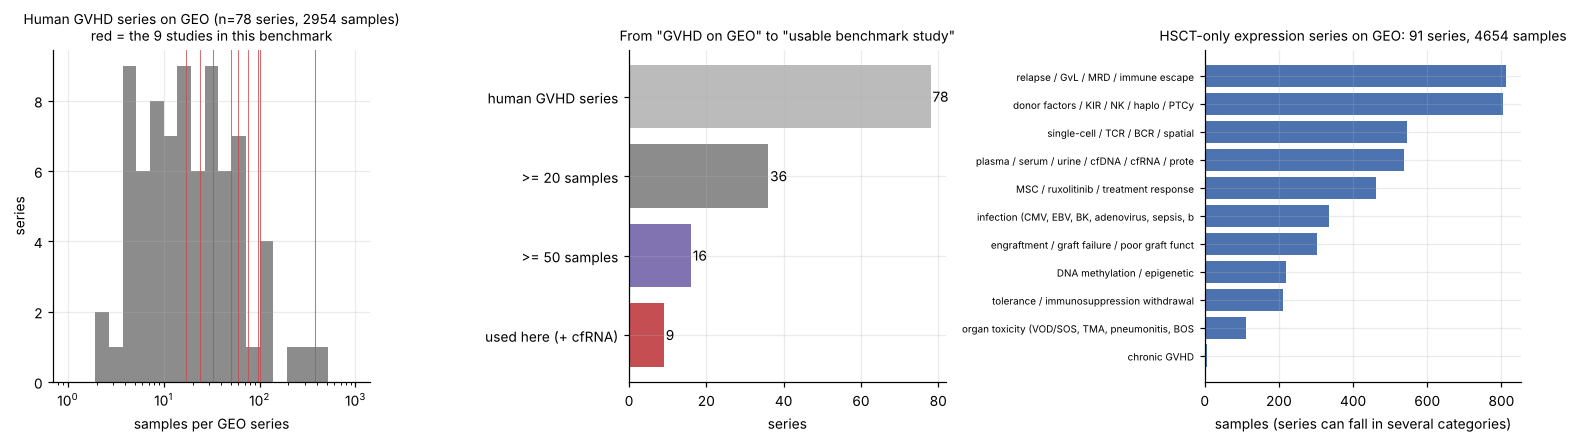

,series,total samples,series >= 20 samples,series >= 50 samples,largest series
GEO search,,,,,
human GVHD (all),78,2954,36,16,400
mouse GVHD,88,1670,13,4,548
non-human primate GVHD,6,340,4,3,107
human organ rejection,45,3476,35,22,572
human alloreactivity/MLR,11,166,4,0,32
human HCT blood/plasma (cfRNA),8,1369,6,6,400


In [3]:
# ---------------------------------------------------------------- Public-data census (GEO E-utilities scans run during this project; trimmed copy in the repo)
CEN = json.load(open(os.path.join(DATA_DIR, 'geo_census.json')))
INFO = json.load(open(os.path.join(DATA_DIR, 'bundle_info.json')))
rows = []
for k, v in CEN['supply'].items():
    n = np.array([x[1] for x in v]); rows.append({'GEO search': k, 'series': len(v), 'total samples': int(n.sum()), 'series >= 20 samples': int((n >= 20).sum()),
                                                  'series >= 50 samples': int((n >= 50).sum()), 'largest series': int(n.max()) if len(n) else 0})
supply_tab = pd.DataFrame(rows).set_index('GEO search')
hs = {k: (len(v), sum(x[1] for x in v)) for k, v in CEN['hsct'].items()}
fig, ax = plt.subplots(1, 3, figsize=(14, 4.1))
n_h = np.array([x[1] for x in CEN['supply']['human GVHD (all)']]); used = {d: int(INFO[d]['n_samples']) for d in INFO}
ax[0].hist(n_h[n_h > 0], bins=np.logspace(0, 3, 22), color='#8C8C8C'); ax[0].set_xscale('log'); ax[0].set_xlabel('samples per GEO series'); ax[0].set_ylabel('series')
for d, nn in used.items(): ax[0].axvline(nn, color='#C44E52', lw=.7, alpha=.8)
ax[0].set_title(f'Human GVHD series on GEO (n={len(n_h)} series, {n_h.sum()} samples)\nred = the 9 studies in this benchmark', fontsize=9)
steps = [('human GVHD series', len(n_h)), ('>= 20 samples', int((n_h >= 20).sum())), ('>= 50 samples', int((n_h >= 50).sum())), ('used here (+ cfRNA)', len(INFO))]
ax[1].barh([s[0] for s in steps][::-1], [s[1] for s in steps][::-1], color=['#C44E52', '#8172B2', '#8C8C8C', '#BBBBBB']); ax[1].set_xlabel('series'); ax[1].set_title('From "GVHD on GEO" to "usable benchmark study"', fontsize=9)
for i, s in enumerate(steps[::-1]): ax[1].text(s[1] + .5, i, str(s[1]), va='center', fontsize=9)
cats = [(k, v) for k, v in hs.items() if k != 'ALL HSCT (denominator)' and v[0] > 0]; cats = sorted(cats, key=lambda kv: -kv[1][1])
ax[2].barh([c[0][:46] for c in cats][::-1], [c[1][1] for c in cats][::-1], color='#4C72B0'); ax[2].set_xlabel('samples (series can fall in several categories)'); ax[2].set_title(f'HSCT-only expression series on GEO: {hs["ALL HSCT (denominator)"][0]} series, {hs["ALL HSCT (denominator)"][1]} samples', fontsize=9)
ax[2].tick_params(axis='y', labelsize=6.5); plt.tight_layout(); plt.show(); supply_tab

**Reading the census.**
* Public GvHD expression data is **dozens of small studies, not one large resource**: the median series has only a handful of samples, and only a minority have ≥20.
* The one large series is plasma **cfRNA (GSE268164: 400 samples, 92 patients, longitudinal)**; the largest *labelled blood T-cell* study has 101 samples.
* Single-cell studies exist but the ones examined here carry **≤ 13 patients**; the BMT CTN 1703 records (randomised PtCy vs Tac/MTX) on GEO/BioProject are **dbGaP controlled-access**.
* For *pretraining* (unlabelled data) the supply is far better — individual public immune atlases hold 10⁵–10⁶ cells each (table below) — but **none of that is allo-HSCT**.

**Unlabelled pretraining supply** (public CELLxGENE Discover collections surveyed during the project; counts as listed in the collection records; none is allo-HSCT):

| Collection | Cells | Tissue / disease |
|---|---|---|
| COVID-19 atlas (Ren et al.) | 1,462,702 | blood, lung, saliva |
| SLE PBMC (Perez et al.) | 1,263,676 | blood |
| COMBAT COVID-19 / influenza / sepsis blood atlas | 836,148 | blood |
| COVID-19 multi-omic (Stephenson et al.) | 647,366 | blood |
| Crohn's disease atlas — terminal-ileum immune / colon immune | 201,072 / 152,509 | ileum / colon (healthy + Crohn's) |
| CD19 CAR-T infusion products | 133,405 | T cells |
| COVID-19 / influenza type-I IFN | 59,572 | blood |
| Human lung-allograft biopsies (tagged "acute GvHD"/normal in the record) | 56,676 | lung |
| IBD / healthy colon 10x | 46,700 | colon |

Roughly **10⁶–10⁷ immune cells** are one download away — enough for O1/O2/O3 at modest scale, orders of magnitude below the 3×10⁷–10⁸ cells of the generalist FMs in A.1, and, per the scale study cited there, scale may not be the binding constraint anyway. The binding constraint is the **labelled allo-HSCT side**, which Part D.1 quantifies.

---
# Part C — Training objectives: what could a GvHD foundation model learn, and from what?

A pretraining objective is only useful if (i) it can be *computed from data that exists*, (ii) its loss is *not trivially solved by a linear model* (otherwise the network adds nothing), and (iii) the representation it produces is *useful for a downstream task we can score*. Table C.1 lays out eight candidates; C.2 gives the precise definitions; C.3 ledgers what our own earlier runs say.

## C.1 Candidate objectives

| # | Objective | Needs | Intrinsic metric (no clinical label) | Downstream tasks it should help | Main failure mode | Public data today |
|---|---|---|---|---|---|---|
| O1 | **Masked expression modelling** (value regression; scGPT/scFoundation/BulkRNABert style) | any expression matrices | held-out-donor masked-gene MSE vs *zero-predictor* and *PCA-ridge* | all diagnostic/prognostic heads | decoder solves it with gene–gene correlation a PCA already captures | ✔ plentiful (10⁷ cells) |
| O2 | **Rank-value masked-token prediction** (Geneformer) | counts-like data | masked-token top-k accuracy vs frequency prior | cell-state / network tasks | rank encoding discards magnitude; breaks on microarray / bulk FPKM inputs | ✔ (RNA-seq only) |
| O3 | **Context-supervised multi-task** (tissue, cell type, disease context: healthy / inflamed / alloimmune) | weakly-labelled atlases | balanced accuracy vs PCA-logistic | zero-shot context identity, cross-organ transfer | context labels are batch-confounded | ◐ (alloimmune sources are few) |
| O4 | **Contrastive / invariance** (same patient across timepoints, same class across studies; InfoNCE) | longitudinal or multi-site pairs | alignment/uniformity; study-ID decodability ↓ | cross-study transfer (the failure we measure in Part E) | collapses biology with batch if positives are mis-specified | ◐ (cfRNA is the only longitudinal set) |
| O5 | **Knowledge-prior bottleneck** (Hallmark / immune gene-set layer, fine-tuned toward a prior) | curated sets | none needed (fixed) | small-n heads (fewer free parameters) | prior is generic; GvHD biology may not be in it | ✔ |
| O6 | **Longitudinal forecasting** p(x_{t+1} \| x_{≤t}, c) | serial samples | R² vs *population-mean* and *persistence* baselines | early warning, trajectory risk | between-patient variance dominates; persistence is hard to beat | ◐ (cfRNA, 92 patients) |
| O7 | **TCR ↔ transcript alignment** (CLIP-style) | paired scRNA + TCR | retrieval accuracy | donor-reactive clone calling, clonal-state tasks | very few paired allo-HSCT sets | ✘ mostly restricted |
| O8 | **Counterfactual / perturbation** (in-silico deletion or drug response) | perturbation screens in primary T cells, JAK-inhibitor stimulation data | held-out-perturbation direction accuracy vs additive baseline | ruxolitinib / steroid response, target discovery | FM perturbation predictions have not beaten linear baselines in published audits (A.2) | ◐ |

## C.2 Definitions (so that the objective is precise, not a slogan)

Let a sample have expression vector $x\in\mathbb{R}^G$, optional context $c$ (tissue, sorted population, platform), patient $p$ and time $t$.

* **O1 — masked value regression.** Draw a mask $M\subset\{1..G\}$ ($|M|\approx 15\%$): $\;\mathcal L_{1}=\mathbb{E}\,\frac{1}{|M|}\sum_{i\in M}\big(x_i-f_\theta(x_{\setminus M},c)_i\big)^2$.
* **O2 — rank-value token prediction.** Let $r(x)$ be the genes ordered by $x_i/\mathrm{median}_i$; with $t_j$ the token at rank $j$: $\;\mathcal L_{2}=-\mathbb{E}\sum_{j\in M}\log p_\theta(t_j\mid t_{\setminus M})$.
* **O3 — context heads.** $\;\mathcal L_{3}=-\mathbb{E}\log p_\theta(\text{ctx}\mid z)$, with $z=g_\theta(x)$ and context classes {healthy, inflamed, alloimmune}.
* **O4 — contrastive.** For positives $(x_a,x_b)$ (same patient, different time; or same class, different study): $\;\mathcal L_{4}=-\log\frac{\exp(\mathrm{sim}(z_a,z_b)/\tau)}{\sum_{k}\exp(\mathrm{sim}(z_a,z_k)/\tau)}$, plus an adversarial or gradient-reversal term that penalises decodability of the study ID from $z$.
* **O5 — pathway bottleneck.** $z=A x$ with $A=A_0+\Delta$, $A_0\in\{0,1/|S_k|\}^{K\times G}$ the Hallmark membership matrix: $\;\mathcal L_{5}=\mathcal L_{\text{task}}+\lambda\lVert\Delta\rVert_F^2$ (λ→∞ recovers the fixed 50-parameter pathway head tested in Part E).
* **O6 — forecasting.** $\;\mathcal L_{6}=\mathbb{E}\,\lVert x_{t+1}-h_\theta(z_{\le t},c,\Delta t)\rVert^2$; scored against persistence $x_t$ and the population mean.
* **O7 — TCR↔transcript.** Symmetric InfoNCE between a clone's CDR3 embedding and its cell-state embedding.
* **O8 — counterfactual.** $\;\mathcal L_{8}=\mathbb{E}\,\lVert x^{\text{post}}-f_\theta(x^{\text{pre}},\text{perturbation})\rVert^2$; scored against the additive baseline $x^{\text{pre}}+\bar\delta$.

**A design principle that follows from A.2.** For each objective the benchmark reports the *intrinsic* metric **and** the downstream transfer. Published zero-shot audits (Kedzierska et al.) found pretrained embeddings that were outperformed by simple baselines even though the pretraining objective had been learned; our own Step-2 run (C.3) shows the same dissociation between a well-fit objective and no downstream gain.

## C.3 Ledger of what our own earlier runs say about these objectives (NOT re-executed in this notebook)

Logs are committed under `benchmark/evidence/`. All are patient-grouped, with controls; "n" is small throughout.

| Earlier experiment (public data, patient-grouped, with controls) | Objective tested | Result | Reading |
|---|---|---|---|
| **Own Perceiver-style T-cell encoder**, pretrained on held-out-donor healthy/inflamed/alloimmune T-cell atlases (`step2_own_encoder_RUN_REPORT.md`) | O1 + O3 | *Intrinsic:* masked-gene MSE **0.689** vs zero-predictor 1.034 vs PCA-ridge 0.910 (objective is learned). Context head balanced accuracy **0.49 = PCA-logistic 0.49**. *Downstream:* FM features above chance on **0 / 8** tasks; LOSO **0.38–0.51** vs normalized genes 0.62 and *untrained-encoder control* 0.66 | pre-stated gate **not passed**: a good intrinsic loss did not buy transfer |
| **Frozen Geneformer 10M / 104M / 316M** on PtCy sorted T cells (`geneformer_ptcy_*.log`) | O2 | within-study AUROC CD8 / CD4 Tconv / Treg: genes 0.84 / 0.78 / 0.79; 104M 0.75 / 0.77 / 0.68; 316M 0.77 / 0.76 / 0.69; random-weight twins 0.49–0.93 (Treg n=20 is pure noise) | pretrained ≥ random in CD8 / CD4; **no arm beats normalized genes** (re-run on more studies in Part E) |
| **LLM gene-text prior** (Qwen3-Embedding vectors of UniProt text → modules / projections) (`llm_gene_text_prior.log`, `colon_llm_prior.log`) | O5 variant | mean over 8 tasks: genes 0.704; LLM modules 0.651 vs *random modules* 0.619; LLM PCs 0.656 vs random PCs 0.638; LLM full 0.637 vs random full 0.710. Colon cross-lab: genes 0.85 / 0.82; LLM-PC32 0.86 / 0.87 vs random-PC32 0.84±0.03 / 0.82±0.04 | **LLM prior ≈ random projection**; "dimension reduction per se" explains the small differences |
| **Hallmark-50 pathway scores** as a knowledge prior (`hallmark_eval_4study.log`, `hallmark_control.log`) | O5 | 4-study LOSO: **0.695** vs genes 0.615; **20/20 shuffled-membership controls below** (0.508 ± 0.078) | exploratory, found *after* looking at the 4 studies — **Part E re-tests it on 7 studies under a pre-stated gate** |
| **Transfer from kidney-rejection biopsies** (GSE36059 / GSE21374; solid-organ source, run before the project was scoped to HSCT-only) (`kidney_transfer.log`) | cross-transplant transfer | kidney→kidney sanity AUROC 0.83; zero-shot on GvHD blood tasks 0.35–0.66; adding kidney rows to the pooled training set **lowered** LOSO 0.695 → 0.587 (permuted-label control 0.615 ± 0.050) | no benefit from rejection biopsies |
| **Treatment-response proxies** (`response_steroid_ruxolitinib_proxy.log`) | O8-adjacent | skin day-28 steroid non-response (n=45, 10 non-responders): ridge-Hallmark 0.56 [0.37, 0.77], p=0.34; zero-parameter IFN-γ / IL-6-JAK-STAT / IL-2-STAT5 scores 0.39–0.43; SR-cGVHD bortezomib failure (n=12) 0.47 | **no usable public labelled set** for ruxolitinib/steroid-refractoriness prediction |
| **Cross-lab colon biopsy signal** (`colon_skin_crosslab.log`) | diagnostic transfer | colon A→B 0.85, B→A 0.80; colon→skin 0.86; learning curve flat from n=6 (0.77) to n=33 (0.82); pre-specified IFN-γ/cytotoxic score 0.80 / 0.88 / 0.88 | the **one signal that replicates across labs** — but the skin figures were computed *before* QC found 4 failed skin libraries (E.1b); they are re-estimated in Part E |
| **cfRNA longitudinal** (`cfrna_signal.log`) | prognostic | pre-GVHD samples (PR + D0): AUROC **0.32** [0.14, 0.48]; month 3: 0.73 (p=0.024) — 1 nominal hit among 10 tests; confounders (batch 0.50, library size 0.34–0.59) | no reproducible pre-onset signal in the only large public blood set |
| **TCR sequence → donor-reactive clone** (`tcr_gate0*.log`, `tcr_step1*.log`) | O7 (sequence-only) | CD8, 54 **kidney**-transplant recipients (GSE288648: solid-organ, so only an alloreactivity proxy, not HSCT), 29,147 matched clones: V/J/length 0.612; + CDR3 k-mers 0.645 (within-lineage-decile **0.579**); small transformer 0.646 (0.590); ESM2-35M embedding 0.642 (0.578); CD4: 0.586 / 0.584 | small genuine sequence signal, **no model class beats k-mers**; an ESM2-150M run was not completed |

---
# Part D — GvHD-Bench: a benchmark specification

## D.0 Design goals (each is a lesson from A.2)
1. **Judge FMs where they would be used**: few labels, new study, new platform.
2. **Never report an FM number without its dumb twins**: normalized genes, confounder-only, shuffled-pathway, random-weight network, random projection.
3. **Separate three questions that are usually fused**: *is the objective learned* (Tier 0), *is the representation general* (Tier 1), *does it transfer to a clinical endpoint* (Tiers 2–6).
4. **Fix the gate before the run** and report what happens.

## D.1 The sample-size toolkit ("what N?")
Three questions, three tools. All are computed below, not asserted:

1. **Precision** — how wide is the CI of one AUROC at sample size n? (Hanley–McNeil SE, validated against simulation.)
2. **Power for a comparison** — to claim "FM B beats baseline A" we need a *paired* test: how many patients for ΔAUROC = 0.03 / 0.05 / 0.10? (DeLong test on simulated correlated model scores.)
3. **Development sample size** — Riley et al.'s three criteria (shrinkage ≤ 10 %, optimism in Nagelkerke R² ≤ 0.05, prevalence precision ±0.05) as implemented in `pmsampsize`, for heads with P = 1 … 3,072 free parameters. Criterion 1 is the formula $n = P/[(S-1)\ln(1-R^2_{CS}/S)]$ (its form was confirmed against a published description of `pmsampsize`; the code includes an arithmetic sanity test); criteria 2–3 are implemented from memory of the paper (†) and **must be cross-checked against `pmsampsize` before any publication use**. The model-implied $R^2_{CS}$ is computed by Monte-Carlo from the target AUROC and prevalence.

Hanley-McNeil SE vs simulated SE: ['A=0.75 n1=20 n0=30: 0.073 vs 0.070', 'A=0.75 n1=60 n0=90: 0.042 vs 0.040', 'A=0.75 n1=200 n0=300: 0.023 vs 0.021']


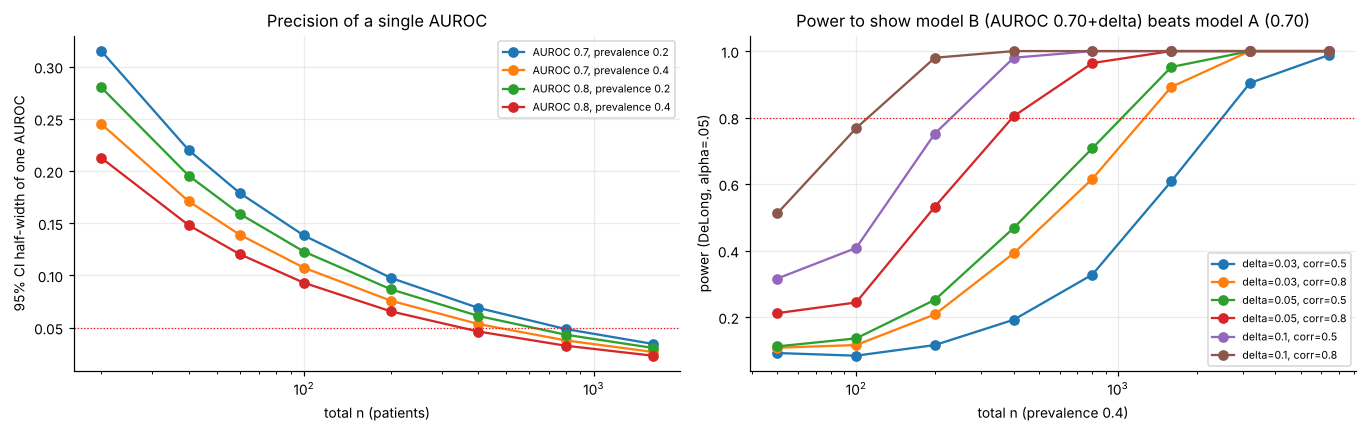

,"AUROC 0.7, prevalence 0.2","AUROC 0.7, prevalence 0.4","AUROC 0.8, prevalence 0.2","AUROC 0.8, prevalence 0.4"
total n,,,,
20,0.315,0.245,0.280,0.213
40,0.220,0.171,0.196,0.148
60,0.179,0.139,0.159,0.120
100,0.138,0.107,0.123,0.093
200,0.098,0.076,0.087,0.066
400,0.069,0.053,0.061,0.046
800,0.049,0.038,0.043,0.033
1600,0.034,0.027,0.031,0.023


,delta_AUROC,score_corr,n=50,n=100,n=200,n=400,n=800,n=1600,n=3200,n=6400,n_for_80pct_power
0,0.03,0.5,0.09,0.08,0.12,0.19,0.33,0.61,0.9,0.99,3200
1,0.03,0.8,0.11,0.12,0.21,0.39,0.62,0.89,1.0,1.00,1600
2,0.05,0.5,0.11,0.14,0.25,0.47,0.71,0.95,1.0,1.00,1600
3,0.05,0.8,0.21,0.24,0.53,0.80,0.96,1.00,1.0,1.00,400
4,0.10,0.5,0.32,0.41,0.75,0.98,1.00,1.00,1.0,1.00,400
5,0.10,0.8,0.51,0.77,0.98,1.00,1.00,1.00,1.0,1.00,200


In [4]:
# ---------------------------------------------------------------- How precise can an AUROC be at a given n?  (Hanley & McNeil 1982 SE, checked against simulation)
from scipy.stats import norm
def hm_se(A, n1, n0):
    Q1, Q2 = A / (2 - A), 2 * A * A / (1 + A)
    return math.sqrt((A * (1 - A) + (n1 - 1) * (Q1 - A * A) + (n0 - 1) * (Q2 - A * A)) / (n1 * n0))
def sim_se(A, n1, n0, reps=1500, seed=0):
    rng = np.random.default_rng(seed); d = math.sqrt(2) * norm.ppf(A)
    return np.std([roc_auc_score(np.r_[np.ones(n1), np.zeros(n0)], np.r_[rng.normal(d, 1, n1), rng.normal(0, 1, n0)]) for _ in range(reps)])
chk = [(0.75, 20, 30), (0.75, 60, 90), (0.75, 200, 300)]
print('Hanley-McNeil SE vs simulated SE:', [f'A={A} n1={a} n0={b}: {hm_se(A, a, b):.3f} vs {sim_se(A, a, b):.3f}' for A, a, b in chk])
ns = np.array([20, 40, 60, 100, 200, 400, 800, 1600])
prec = pd.DataFrame({f'AUROC {A}, prevalence {pi}': [1.96 * hm_se(A, max(int(n * pi), 2), max(int(n * (1 - pi)), 2)) for n in ns] for A in (.7, .8) for pi in (.2, .4)}, index=ns)
prec.index.name = 'total n'
# --- paired power: can we detect that model B (AUROC .70+delta) beats model A (AUROC .70)?  DeLong test, simulated correlated scores
from scipy.stats import rankdata
def delong_paired(y, s1, s2):
    """DeLong test for two correlated AUROCs on the same cases (fast rank-based form of Sun & Xu 2014). Returns the z statistic for AUC2 - AUC1."""
    m, n = int((y == 1).sum()), int((y == 0).sum()); aucs, v01, v10 = [], [], []
    for s in (s1, s2):
        X, Y = s[y == 1], s[y == 0]; tx, ty, tz = rankdata(X), rankdata(Y), rankdata(np.r_[X, Y])
        aucs.append(tz[:m].sum() / (m * n) - (m + 1) / (2 * n)); v01.append((tz[:m] - tx) / n); v10.append(1 - (tz[m:] - ty) / m)
    S = np.cov(np.vstack(v01)) / m + np.cov(np.vstack(v10)) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    return (aucs[1] - aucs[0]) / math.sqrt(max(var, 1e-12))
def delong_slow(y, s1, s2):                                            # O(m*n) textbook version, used once below as a unit test
    pos = y == 1; m, n = pos.sum(), (~pos).sum()
    def comps(s):
        psi = (s[pos][:, None] > s[~pos][None, :]) + .5 * (s[pos][:, None] == s[~pos][None, :]); return psi.mean(), psi.mean(1), psi.mean(0)
    a1, x1, y1 = comps(s1); a2, x2, y2 = comps(s2)
    S = np.cov(np.vstack([x1, x2])) / m + np.cov(np.vstack([y1, y2])) / n
    return (a2 - a1) / math.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1])
_r = np.random.default_rng(0); _y = (_r.random(120) < .4).astype(int); _a, _b = _r.normal(size=120) + _y, _r.normal(size=120) + .6 * _y
assert abs(delong_paired(_y, _a, _b) - delong_slow(_y, _a, _b)) < 1e-9, 'fast and textbook DeLong disagree'
def paired_power(n, pi, A1, A2, rho, reps=300, seed=0):
    rng = np.random.default_rng(seed); n1 = max(int(round(n * pi)), 3); n0 = n - n1; d1, d2 = math.sqrt(2) * norm.ppf(A1), math.sqrt(2) * norm.ppf(A2)
    cov = np.array([[1, rho], [rho, 1]]); hit = 0
    for _ in range(reps):
        sp = rng.multivariate_normal([d1, d2], cov, n1); sn = rng.multivariate_normal([0, 0], cov, n0)
        y = np.r_[np.ones(n1), np.zeros(n0)]; s1 = np.r_[sp[:, 0], sn[:, 0]]; s2 = np.r_[sp[:, 1], sn[:, 1]]
        hit += abs(delong_paired(y, s1, s2)) > 1.96
    return hit / reps
grid = [50, 100, 200, 400, 800, 1600, 3200, 6400]; pw_rows = []
for delta in (.03, .05, .10):
    for rho in (.5, .8):
        pw = [paired_power(n, .4, .70, .70 + delta, rho, reps=N_POWER) for n in grid]
        n80 = next((n for n, p in zip(grid, pw) if p >= .8), None); pw_rows.append(dict(delta_AUROC=delta, score_corr=rho, **{f'n={n}': p for n, p in zip(grid, pw)}, n_for_80pct_power=n80 if n80 else f'>{grid[-1]}'))
pw_tab = pd.DataFrame(pw_rows)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
for c in prec.columns: ax.flat[0].plot(prec.index, prec[c], marker='o', label=c)
ax[0].set_xscale('log'); ax[0].axhline(.05, color='r', ls=':', lw=.8); ax[0].set_xlabel('total n (patients)'); ax[0].set_ylabel('95% CI half-width of one AUROC'); ax[0].set_title('Precision of a single AUROC'); ax[0].legend(fontsize=7)
for i, r in pw_tab.iterrows(): ax[1].plot(grid, [r[f'n={n}'] for n in grid], marker='o', label=f'delta={r.delta_AUROC}, corr={r.score_corr}')
ax[1].axhline(.8, color='r', ls=':', lw=.8); ax[1].set_xscale('log'); ax[1].set_xlabel('total n (prevalence 0.4)'); ax[1].set_ylabel('power (DeLong, alpha=.05)'); ax[1].set_title('Power to show model B (AUROC 0.70+delta) beats model A (0.70)'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show(); display(prec.round(3)); display(pw_tab.round(2))

In [5]:
display(Markdown(f"""**Reading.** Hanley–McNeil's closed-form SE matches the simulated SE to within ~0.003, so the table is trustworthy. At n = 100 and AUROC 0.70 the CI is ±{prec.loc[100, 'AUROC 0.7, prevalence 0.4']:.2f}; even n = 400 gives ±{prec.loc[400, 'AUROC 0.7, prevalence 0.4']:.2f}. Detecting a ΔAUROC of 0.05 between two *correlated* models needs {pw_tab[(pw_tab.delta_AUROC == .05) & (pw_tab.score_corr == .8)].n_for_80pct_power.iloc[0]}–{pw_tab[(pw_tab.delta_AUROC == .05) & (pw_tab.score_corr == .5)].n_for_80pct_power.iloc[0]} patients; Δ = 0.03 needs {pw_tab[(pw_tab.delta_AUROC == .03) & (pw_tab.score_corr == .8)].n_for_80pct_power.iloc[0]}–{pw_tab[(pw_tab.delta_AUROC == .03) & (pw_tab.score_corr == .5)].n_for_80pct_power.iloc[0]}. *Correlated* is the important word: an FM and a linear model on the same genes share most of their errors (corr ≈ 0.8), which makes small improvements easier to detect — but equally makes them smaller."""))

**Reading.** Hanley–McNeil's closed-form SE matches the simulated SE to within ~0.003, so the table is trustworthy. At n = 100 and AUROC 0.70 the CI is ±0.11; even n = 400 gives ±0.05. Detecting a ΔAUROC of 0.05 between two *correlated* models needs 400–1600 patients; Δ = 0.03 needs 1600–3200. *Correlated* is the important word: an FM and a linear model on the same genes share most of their errors (corr ≈ 0.8), which makes small improvements easier to detect — but equally makes them smaller.

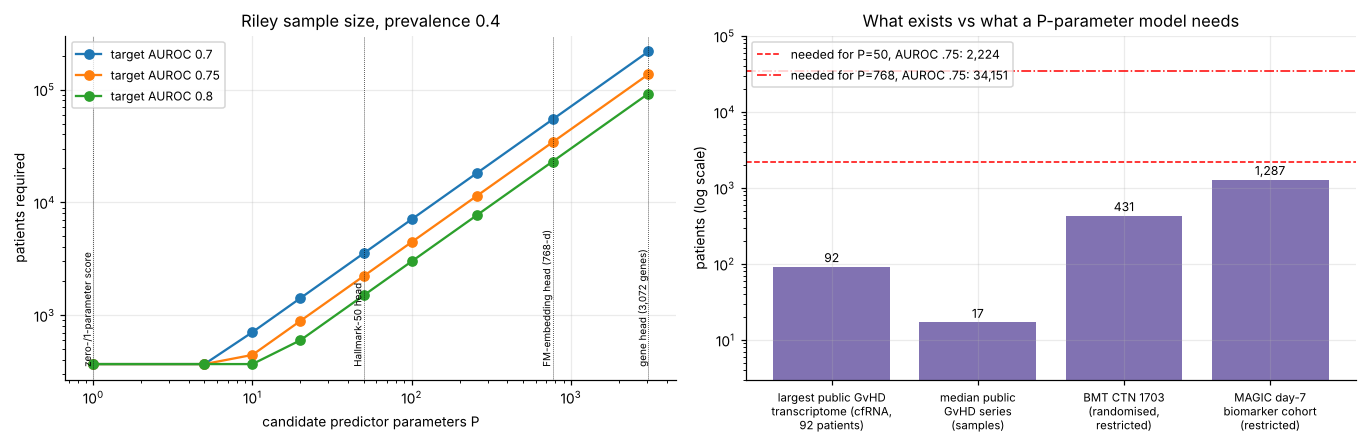

AUROC,0.70,0.75,0.80
params,,,
1,369,369,369
5,369,369,369
10,708,445,369
20,1416,890,600
50,3539,2224,1500
100,7078,4447,2999
256,18120,11384,7677
768,54358,34151,23029
3072,217430,136601,92114


In [6]:
# ---------------------------------------------------------------- Sample size to DEVELOP a prediction model (Riley et al. criteria, as implemented in `pmsampsize`)
def r2cs_from_auc(A, prev, n_mc=1_000_000, seed=0):
    """Model-implied Cox-Snell R^2 for a perfectly calibrated model with a given AUROC and outcome prevalence (equal-variance binormal LP)."""
    rng = np.random.default_rng(seed); d = math.sqrt(2) * norm.ppf(A)
    y = rng.random(n_mc) < prev; x = np.where(y, rng.normal(d, 1, n_mc), rng.normal(0, 1, n_mc))
    lp = math.log(prev / (1 - prev)) + d * x - d * d / 2; p = 1 / (1 + np.exp(-lp))
    ll1 = np.mean(np.where(y, np.log(p), np.log(1 - p))); ll0 = prev * math.log(prev) + (1 - prev) * math.log(1 - prev)
    return 1 - math.exp(-2 * (ll1 - ll0))
def riley_n(P, A, prev, S=.9, delta=.05, margin=.05):
    r2 = r2cs_from_auc(A, prev); max_r2 = 1 - math.exp(2 * (prev * math.log(prev) + (1 - prev) * math.log(1 - prev)))
    n1 = P / ((S - 1) * math.log(1 - r2 / S))                                    # (1) expected shrinkage <= 10 %
    S2 = r2 / (r2 + delta * max_r2); n2 = P / ((S2 - 1) * math.log(1 - r2 / S2)) # (2) optimism in Nagelkerke R^2 <= 0.05
    n3 = (1.96 / margin) ** 2 * prev * (1 - prev)                                # (3) overall risk estimated within +/-0.05
    n = max(n1, n2, n3); return dict(n=int(math.ceil(n)), events=int(math.ceil(n * prev)), EPP=round(n * prev / P, 1), binding=['shrinkage', 'optimism', 'prevalence'][int(np.argmax([n1, n2, n3]))])
# arithmetic sanity test of criterion 1 for a hand-computed case (R2_CS = 0.288, 24 parameters -> 623 participants); NOT an external validation against pmsampsize
assert abs(24 / ((0.9 - 1) * math.log(1 - 0.288 / 0.9)) - 623) < 1.5
PARAMS = [1, 5, 10, 20, 50, 100, 256, 768, 3072]
riley_rows = []
for prev in (.2, .4):
    for A in (.70, .75, .80):
        riley_rows += [dict(prevalence=prev, AUROC=A, params=P, **riley_n(P, A, prev)) for P in PARAMS]
riley = pd.DataFrame(riley_rows)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.1))
for A in (.70, .75, .80):
    q = riley[(riley.prevalence == .4) & (riley.AUROC == A)]; ax[0].plot(q.params, q.n, marker='o', label=f'target AUROC {A}')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('candidate predictor parameters P'); ax[0].set_ylabel('patients required'); ax[0].set_title('Riley sample size, prevalence 0.4')
for P, lab in ((1, 'zero-/1-parameter score'), (50, 'Hallmark-50 head'), (768, 'FM-embedding head (768-d)'), (3072, 'gene head (3,072 genes)')): ax[0].axvline(P, color='k', lw=.5, ls=':'); ax[0].text(P, ax[0].get_ylim()[0] * 1.3, lab, rotation=90, fontsize=6.5, va='bottom', ha='right')
ax[0].legend(fontsize=8)
have = {'largest public GvHD\ntranscriptome (cfRNA,\n92 patients)': 92, 'median public\nGvHD series\n(samples)': int(np.median([x[1] for x in CEN['supply']['human GVHD (all)']])), 'BMT CTN 1703\n(randomised,\nrestricted)': 431, 'MAGIC day-7\nbiomarker cohort\n(restricted)': 1287}
bars = ax[1].bar(range(len(have)), list(have.values()), color='#8172B2'); ax[1].set_xticks(range(len(have))); ax[1].set_xticklabels(list(have), fontsize=7.5); ax[1].set_yscale('log'); ax[1].set_ylim(3, 1e5)
for b_, v_ in zip(bars, have.values()): ax[1].text(b_.get_x() + b_.get_width() / 2, v_ * 1.15, f'{v_:,}', ha='center', fontsize=8)
for P, ls in ((50, '--'), (768, '-.')):
    nreq = riley[(riley.prevalence == .4) & (riley.AUROC == .75) & (riley.params == P)].n.iloc[0]; ax[1].axhline(nreq, color='r', ls=ls, lw=1, label=f'needed for P={P}, AUROC .75: {nreq:,}')
ax[1].set_ylabel('patients (log scale)'); ax[1].set_title('What exists vs what a P-parameter model needs'); ax[1].legend(fontsize=8, loc='upper left'); plt.tight_layout(); plt.show()
riley[(riley.prevalence == .4)].pivot(index='params', columns='AUROC', values='n')

In [7]:
display(Markdown(f"""**Reading.** For a calibrated model with AUROC 0.75 at prevalence 0.4 the unpenalised requirement is about **{riley_n(1, .75, .4)['n']} patients for a 1–5-parameter score** (prevalence-precision criterion binds), then ≈ **{round(riley_n(50, .75, .4)['n'] / 50)} patients per parameter** thereafter — i.e. {riley_n(10, .75, .4)['n']} for 10 parameters, {riley_n(50, .75, .4)['n']:,} for 50, {riley_n(768, .75, .4)['n']:,} for a 768-d embedding head. Two caveats: these formulae assume an unpenalised model (ridge shrinkage reduces the effective parameter count — the empirical curves in E.10 are the complement), and they are for *developing* a model, not for showing that it beats another."""))

**Reading.** For a calibrated model with AUROC 0.75 at prevalence 0.4 the unpenalised requirement is about **369 patients for a 1–5-parameter score** (prevalence-precision criterion binds), then ≈ **44 patients per parameter** thereafter — i.e. 445 for 10 parameters, 2,224 for 50, 34,151 for a 768-d embedding head. Two caveats: these formulae assume an unpenalised model (ridge shrinkage reduces the effective parameter count — the empirical curves in E.10 are the complement), and they are for *developing* a model, not for showing that it beats another.

## D.2 Task registry — what a GvHD FM can be asked to do, and how each task is scored

*Minimum n* in the last two columns comes from the Riley calculator above for a **50-parameter head** (e.g. pathway scores) and a **768-parameter head** (e.g. a frozen-FM embedding), at the stated target AUROC and *assumed* prevalence. Time-to-event tasks use events-per-parameter analogues; treat those as order-of-magnitude. The "public today" column is what this project actually found.

In [8]:
# ---------------------------------------------------------------- GvHD-Bench task registry (machine-readable; the Riley columns are computed, not typed)
R = lambda P, A, prev: riley_n(P, A, prev)['n']
REGISTRY = [
 # id, tier, question, input @ time, label / horizon, split, primary metric, must-beat baselines, prevalence*, target AUROC, public data today
 ('T0.1', '0 intrinsic', 'Is the pretraining objective learned?', 'expression, held-out donors', 'masked genes', 'held-out DONORS', 'masked-gene MSE', 'zero-predictor, PCA-ridge', None, None, 'yes (atlases)'),
 ('T0.2', '0 intrinsic', 'Context identity (healthy / inflamed / alloimmune)', 'expression', 'context class', 'held-out donors + studies', 'balanced accuracy', 'majority prior, PCA-logistic', None, None, 'partly'),
 ('T1.1', '1 zero-shot', 'Compartment / cell-type identity across studies', 'sorted-population bulk or pseudobulk', 'CD8 / CD4 / Treg / NK', 'no head trained (kNN, silhouette)', '5-NN accuracy, ASW', 'HVG-2000, PCA, random-weight network', None, None, 'yes (PtCy, GSE103569)'),
 ('T1.2', '1 zero-shot', 'Batch / study removal while keeping biology', 'same', 'study / sequencing batch', 'no head trained', 'scIB-style 2-axis score', 'same', None, None, 'yes'),
 ('T2.1', '2 diagnostic', 'GvHD present at sampling — blood / T cell', 'sorted or PBMC T-cell transcriptome', 'aGvHD vs none at sampling', 'leave-one-STUDY-out + k-shot', 'AUROC (+AUPRC), patient-bootstrap CI', 'genes, confounder-only, shuffled-pathway', .45, .75, 'yes: 4 studies, 220 samples'),
 ('T2.2', '2 diagnostic', 'GvHD present at sampling — tissue biopsy', 'GI / skin biopsy transcriptome', 'GvHD vs no GvHD', 'LOSO + cross-ORGAN (colon↔skin)', 'AUROC', 'genes, zero-parameter IFN-γ score', .5, .80, 'yes: 3 studies, 104 samples'),
 ('T2.3', '2 diagnostic', 'Which organ is involved (gut / skin / liver)', 'T-cell homing subsets or biopsy', 'organ label', 'LOSO', 'macro-AUROC', 'genes', .33, .75, 'minimal (GSE103569 labels)'),
 ('T3.1', '3 landmark', 'P(grade II–IV aGvHD by d+100 | blood at d+7 or d+14)', 'whole blood / PBMC / plasma cfRNA', 'aGvHD grade II–IV, competing risk: death/relapse', 'landmark; LOSO + leave-CENTRE-out', 'time-dependent AUROC, calibration slope, decision curve', 'clinical-only, Ann Arbor/MAGIC biomarkers, genes', .35, .75, 'NO (cfRNA: no onset dates; labels are patient-level "ever")'),
 ('T3.2', '3 landmark', 'Steroid refractoriness at d+28 | sample at diagnosis', 'biopsy or blood at GvHD onset', 'non-response vs response d28', 'LOSO', 'AUROC, calibration', 'clinical-only (grade, MAGIC)', .25, .75, 'weak: skin n=45 (10 NR)'),
 ('T3.3', '3 landmark', 'Relapse by 1 y | sample at d+30', 'blood / cfRNA', 'relapse', 'landmark; LOSO', 'time-dependent AUROC, C-index', 'disease risk index, MRD', .25, .75, 'weak (cfRNA relapse labels, no dates)'),
 ('T3.4', '3 landmark', 'Non-relapse mortality / OS', 'blood at d+7', 'time-to-event', 'landmark + leave-centre-out', 'C-index, IBS, calibration', 'MAGIC algorithm probability', .2, .75, 'NO (BMT CTN / MAGIC / CIBMTR: restricted)'),
 ('T3.5', '3 landmark', 'cGvHD onset | sample at d+100', 'blood', 'NIH-defined cGvHD by 1 y', 'landmark', 'time-dependent AUROC', 'clinical-only, BIOPREVENT-type panel', .3, .70, 'minimal'),
 ('T3.6', '3 landmark', 'Viral reactivation (BKV, CMV)', 'plasma cfRNA', 'reactivation by horizon', 'landmark', 'AUROC', 'clinical-only', .35, .75, 'partly (cfRNA BKV labels)'),
 ('T4.1', '4 response', 'Ruxolitinib / ibrutinib response from pre-treatment blood', 'blood at treatment start', 'response at d+28', 'LOSO', 'AUROC', 'clinical-only', .5, .75, 'NO labelled public set'),
 ('T4.2', '4 mechanism', 'In-silico perturbation: direction of change after JAK inhibition / gene knock-out', 'primary T-cell perturbation data', 'post-perturbation profile', 'held-out PERTURBATIONS', 'direction accuracy, rank correlation', 'additive baseline (Ahlmann-Eltze)', None, None, 'partly (external T-cell screens)'),
 ('T5.1', '5 TCR', 'Donor-reactive clone identification', 'CDR3 + V/J + abundance', 'MLR-defined reactive clones', 'held-out RECIPIENTS; abundance-matched negatives', 'AUROC within lineage deciles', 'V/J/length, k-mers', .17, .65, 'proxy only: GSE288648 is kidney-transplant, not HSCT'),
 ('T5.2', '5 TCR', 'Repertoire-level diagnosis (positive-control task: CMV serostatus)', 'whole repertoire', 'CMV +/−', 'held-out donors', 'AUROC', 'k-mer / public-clone enrichment', .5, .85, 'restricted download (not run)'),
 ('T6.1', '6 longitudinal', 'Forecast the next timepoint', 'serial profiles', 'x(t+1)', 'held-out PATIENTS', 'R² vs population-mean / persistence', 'persistence', None, None, 'yes (cfRNA; executed in E.9)'),
 ('T7.1', '7 robustness', 'Platform shift (array → RNA-seq), centre shift, sub-group performance, calibration', 'any', 'any', 'leave-platform-out, leave-centre-out', 'AUROC gap, calibration slope, DCA net benefit', 'same as parent task', None, None, 'partly'),
]
reg = pd.DataFrame(REGISTRY, columns=['id', 'tier', 'question', 'input @ time', 'label / horizon', 'split', 'primary metric', 'must beat', 'assumed prevalence*', 'target AUROC', 'public data today'])
reg['min n, 50-param head'] = [R(50, a, p) if pd.notna(a) else '' for a, p in zip(reg['target AUROC'], reg['assumed prevalence*'])]
reg['min n, 768-param head'] = [R(768, a, p) if pd.notna(a) else '' for a, p in zip(reg['target AUROC'], reg['assumed prevalence*'])]
pd.set_option('display.max_colwidth', 70, 'display.width', 250)
reg.fillna('').style.set_properties(**{'text-align': 'left', 'white-space': 'normal', 'font-size': '11px'}).hide(axis='index')

id,tier,question,input @ time,label / horizon,split,primary metric,must beat,assumed prevalence*,target AUROC,public data today,"min n, 50-param head","min n, 768-param head"
T0.1,0 intrinsic,Is the pretraining objective learned?,"expression, held-out donors",masked genes,held-out DONORS,masked-gene MSE,"zero-predictor, PCA-ridge",,,yes (atlases),,
T0.2,0 intrinsic,Context identity (healthy / inflamed / alloimmune),expression,context class,held-out donors + studies,balanced accuracy,"majority prior, PCA-logistic",,,partly,,
T1.1,1 zero-shot,Compartment / cell-type identity across studies,sorted-population bulk or pseudobulk,CD8 / CD4 / Treg / NK,"no head trained (kNN, silhouette)","5-NN accuracy, ASW","HVG-2000, PCA, random-weight network",,,"yes (PtCy, GSE103569)",,
T1.2,1 zero-shot,Batch / study removal while keeping biology,same,study / sequencing batch,no head trained,scIB-style 2-axis score,same,,,yes,,
T2.1,2 diagnostic,GvHD present at sampling — blood / T cell,sorted or PBMC T-cell transcriptome,aGvHD vs none at sampling,leave-one-STUDY-out + k-shot,"AUROC (+AUPRC), patient-bootstrap CI","genes, confounder-only, shuffled-pathway",0.450000,0.750000,"yes: 4 studies, 220 samples",2169,33316
T2.2,2 diagnostic,GvHD present at sampling — tissue biopsy,GI / skin biopsy transcriptome,GvHD vs no GvHD,LOSO + cross-ORGAN (colon↔skin),AUROC,"genes, zero-parameter IFN-γ score",0.500000,0.800000,"yes: 3 studies, 104 samples",1450,22262
T2.3,2 diagnostic,Which organ is involved (gut / skin / liver),T-cell homing subsets or biopsy,organ label,LOSO,macro-AUROC,genes,0.330000,0.750000,minimal (GSE103569 labels),2399,36847
T3.1,3 landmark,P(grade II–IV aGvHD by d+100 | blood at d+7 or d+14),whole blood / PBMC / plasma cfRNA,"aGvHD grade II–IV, competing risk: death/relapse",landmark; LOSO + leave-CENTRE-out,"time-dependent AUROC, calibration slope, decision curve","clinical-only, Ann Arbor/MAGIC biomarkers, genes",0.350000,0.750000,"NO (cfRNA: no onset dates; labels are patient-level ""ever"")",2337,35895
T3.2,3 landmark,Steroid refractoriness at d+28 | sample at diagnosis,biopsy or blood at GvHD onset,non-response vs response d28,LOSO,"AUROC, calibration","clinical-only (grade, MAGIC)",0.250000,0.750000,weak: skin n=45 (10 NR),2817,43265
T3.3,3 landmark,Relapse by 1 y | sample at d+30,blood / cfRNA,relapse,landmark; LOSO,"time-dependent AUROC, C-index","disease risk index, MRD",0.250000,0.750000,"weak (cfRNA relapse labels, no dates)",2817,43265


\* *prevalences are assumptions for planning, not measurements.*

## D.3 Protocol — the rules every task obeys

**Units and splits**
* The unit of analysis is the **patient**. A donor–recipient pair counts as one unit when both contribute samples (donor cells → recipient outcome tasks).
* Split hierarchy, strictest first: **leave-one-study-out** (transfer), **leave-centre-out** (site shift), **patient-grouped repeated K-fold** (within-study only), **landmark split** for prognostic tasks (features from samples at or before the landmark; outcomes strictly after it; patients who die/relapse/are censored before the landmark are excluded, and death is treated as a competing event).
* Normalisation is **label-free and block-wise** (z-score within study × sorted population). It uses only the features of the block being normalised — at deployment this requires a batch of samples from the same site/platform (≥ ~15), which is a stated limitation. *No parameter fitted on test labels, ever; the head's penalty C is chosen by patient-grouped inner CV on training data.*

**Metrics**
* Discrimination: AUROC (AUPRC when prevalence < 0.3). Landmark/time-to-event: cumulative/dynamic time-dependent AUROC with inverse-probability-of-censoring weights and competing-risk cumulative incidence; C-index only as a secondary figure.
* Calibration and utility (mandatory for any clinical claim): calibration slope and intercept, Brier score, decision-curve net benefit at 10–40 % thresholds.
* Uncertainty: **patient-cluster bootstrap** CIs; paired DeLong / paired bootstrap for model-vs-baseline differences; **permutation null** by shuffling labels across patients and re-running the entire pipeline; Benjamini–Hochberg across tasks.

**Mandatory comparators in every table** — a result is not reportable without them
1. *Confounder-only model* (batch, library size, array order, site, day post-HCT) — if it matches the FM, the signal is technical.
2. *Normalized genes + ridge-logistic* (the Boiarsky/Kedzierska baseline).
3. *Pathway-prior head* and its **shuffled-membership** control.
4. *Random-projection* head of the same dimension as the FM embedding.
5. *Random-weight twin* of each pretrained network (isolates what pretraining adds).
6. For prognostic tasks: *clinical-only* model and, where available, *Ann Arbor / MAGIC biomarker* scores.

**Leakage audit checklist** (run before any number is shown)
patient overlap across folds · donor–recipient overlap · duplicate samples across GEO series · label ≈ batch/centre correlation · identical sorted populations from one patient on both sides of a split · timing: any feature recorded after the landmark · normalisation statistics computed on pooled train+test · hyper-parameters tuned on the test study.

**Claim ladder** (what the suite lets you *say*)

| Level | Statement permitted | Requirement (all) |
|---|---|---|
| 0 | none | — |
| 1 | "non-inferior, more label-efficient than normalized genes" | LOSO mean within 0.02 of the best simple baseline **and** higher at k ≤ 32 labelled samples (paired over studies) |
| 2 | "superior transfer" | LOSO mean ≥ +0.03 over best simple baseline, study-bootstrap CI excludes 0, beats its random-weight twin, improves ≥ 5/7 held-out studies, survives BH across tasks |
| 3 | "clinically useful prognostic model" | Level 2 **plus** a landmark task that beats clinical-only + biomarker models in leave-centre-out evaluation, with calibration and decision-curve benefit, at the sample size the Riley calculator requires |

## D.4 The pre-stated gate for this notebook's proof-of-concept
The rule below was written to disk **before** the 7-study benchmark was first executed (the script's log was empty until the run reported in Part E). It is the "Level 2" test restricted to the three designs on the table.

In [9]:
# ---------------------------------------------------------------- Pre-registration, in code.  These rules were written to disk BEFORE the benchmark was first run.
GATE = dict(
    primary_endpoint='leave-one-STUDY-out AUROC for "GVHD present in the patient at sampling", 7 studies, features z-scored within (study x compartment) blocks (label-free)',
    designs={'genes': '3,072 vocabulary genes, ridge-logistic head (the generic baseline)',
             'path50': 'MSigDB Hallmark 50 pathway scores, ridge-logistic head (knowledge prior)',
             'moe50': 'path50 + path50 x [tissue] (shared head + sample-type expert)'},
    control='path50 with shuffled gene membership, 20 replicates',
    works_if=['mean LOSO AUROC >= 0.70', 'mean >= genes + 0.05', 'mean > 95th percentile of the shuffled-membership control', '>= 5 of 7 held-out studies with AUROC > 0.60'])
for k, v in GATE.items(): print(f'{k:18s}', v)

primary_endpoint   leave-one-STUDY-out AUROC for "GVHD present in the patient at sampling", 7 studies, features z-scored within (study x compartment) blocks (label-free)
designs            {'genes': '3,072 vocabulary genes, ridge-logistic head (the generic baseline)', 'path50': 'MSigDB Hallmark 50 pathway scores, ridge-logistic head (knowledge prior)', 'moe50': 'path50 + path50 x [tissue] (shared head + sample-type expert)'}
control            path50 with shuffled gene membership, 20 replicates
works_if           ['mean LOSO AUROC >= 0.70', 'mean >= genes + 0.05', 'mean > 95th percentile of the shuffled-membership control', '>= 5 of 7 held-out studies with AUROC > 0.60']


## D.5 Reporting (TRIPOD+AI) and release

Report the 27 TRIPOD+AI items; additionally release (i) the **data card** (accession, platform, label definition, sampling time relative to GvHD onset, known confounders), (ii) the **frozen split files** and the permutation/bootstrap seeds, (iii) a **model card** stating the pretraining corpus and the normalisation each deployment site must run, and (iv) the **negative results** table (what did not beat the baselines).

---
# Part E — Executed proof-of-concept: the suite run on 9 public studies

**What is run.** Tiers 1–3 and 6 of GvHD-Bench, for the tasks whose data are public: 838 samples (after QC), 9 studies, 3 platforms (microarray, bulk/pseudobulk RNA-seq, plasma cfRNA-seq), blood and tissue.
**What is not run.** Tiers 0 and 4–5 and landmark prognosis (no public labels/timing) — those are specified in Part D and scoped in Part F.
**Data.** `benchmark/data/` holds the analysis-ready bundle (log-scale expression for the 3,072 pipeline-vocabulary genes ∪ Hallmark members, plus metadata). `benchmark/build_bundle.py` is the script as-run that produced it from the GEO files; accessions and caveats are in the data card below.

## E.1 Data card

| Study (GEO) | Sample / platform | Label used | Role here | Known caveats |
|---|---|---|---|---|
| **GSE73809** | PBMC CD4+CD8 T cells, Affymetrix HTA 2.0 | aGvHD vs matched controls, d28–176 | diagnostic LOSO + within-study | n=24; batch/site/day-post-HCT confounders |
| **GSE103569** | FACS CD8 subsets (reference / skin-homing / gut-homing), Agilent array | GvHD present | diagnostic LOSO + within-study | 60 samples from **20 patients** (3 per patient); 75 % positive |
| **PtCy: GSE182610 + GSE182612 + GSE182678** | FACS CD8 / CD4 Tconv / Treg (+NK), bulk RNA-seq, 4 sequencing batches | GvHD at sampling (all patients received post-transplant cyclophosphamide) | diagnostic LOSO (NK excluded) + within-study | **GEO provides no patient IDs** (one ID per sample; independence unverified); sampling time vs onset unknown |
| **GSE295359** | scRNA-seq pseudobulk (T_all / CD4 / CD8), D30 / D100 only | GvHD | diagnostic LOSO + within-study | **10 patients** × timepoints × compartments; Zenodo release limited to 3,072 genes (not Geneformer-compatible) |
| **GSE215068** | colon biopsy, FFPE bulk RNA-seq | GvHD vs no GvHD | diagnostic LOSO + within-study | n=33; FFPE |
| **GSE168116** | paediatric rectosigmoid biopsy, bulk RNA-seq (TPM) | GvHD vs no GvHD | diagnostic LOSO + within-study | n=17 |
| **GSE263557** | skin biopsy, bulk RNA-seq (log₂ FPKM supplementary matrix) | GvHD (n=45) vs control skin (n=9); day-28 steroid non-response among GvHD | diagnostic LOSO; **prognostic** within-study (NR, 10 non-responders) | 83 % positive; library-prep order as confounder check |
| **GSE4624** | donor CD4 / CD8 T cells, array | **recipient** aGvHD (prognostic) | within-study only | 96 samples / 51 donors; array order confounds |
| **GSE268164** | plasma cfRNA-seq, longitudinal (PR, D0, 1M, 2M, 3M, 6M, E) | patient-level "ever aGvHD" repeated at each timepoint | within-study prognostic-style tasks; forecasting | **92 patients**; onset date not in GEO, so not a true landmark task; batch / library-size confounders |

In [10]:
# ---------------------------------------------------------------- load the analysis-ready bundle
B = np.load(os.path.join(DATA_DIR, 'hsct_bundle.npz'), allow_pickle=False)
KEEP = [str(g) for g in B['genes']]
S = pd.read_csv(os.path.join(DATA_DIR, 'hsct_samples.csv'))
HALLMARK = json.load(open(os.path.join(DATA_DIR, 'hallmark50.json'))); HNAMES = sorted(HALLMARK)
VG = json.load(open(os.path.join(DATA_DIR, 'vocab_genes.json')))                    # the 3,072 "T-cell vocabulary" genes of the pipeline
INFO = json.load(open(os.path.join(DATA_DIR, 'bundle_info.json')))
kpos = {g: i for i, g in enumerate(KEEP)}
vidx = np.array([kpos[g] for g in VG])
print(f'{len(S)} samples in {S.study.nunique()} studies; {len(KEEP)} genes in bundle ({len(VG)} vocabulary genes, {len(HNAMES)} Hallmark sets)')

RAW = {}
for name in S.study.unique():
    m = S[S.study == name].reset_index(drop=True)
    assert list(B['sid_' + name]) == list(m.sid.astype(str)), name
    RAW[name] = dict(meta=m, X=B['X_' + name].astype(np.float64))

def zblock(X, blocks):
    """Label-free per-gene z-score inside each (study x compartment) block.  Unmeasured genes -> 0."""
    X = np.asarray(X, float).copy()
    measured = np.isfinite(X).any(0)
    med = np.nanmedian(np.where(np.isfinite(X), X, np.nan), axis=0); med = np.where(np.isfinite(med), med, 0.0)
    X = np.where(np.isfinite(X), X, med[None, :])
    for b in np.unique(blocks):
        i = blocks == b
        X[i] = (X[i] - X[i].mean(0)) / np.maximum(X[i].std(0), 1e-6)
    return X, measured

def hallmark_scores(Z, measured, sets=None, names=None, min_members=10):
    """Mean z-score of the member genes the platform actually measures (score := 0 when fewer than `min_members` are measured)."""
    sets = sets or HALLMARK; names = names or HNAMES
    H = np.zeros((len(Z), len(names)))
    for j, n in enumerate(names):
        idx = [kpos[g] for g in sets[n] if g in kpos and measured[kpos[g]]]
        if len(idx) >= min_members: H[:, j] = Z[:, idx].mean(1)
    return H

def featurize(name, rows=None):
    """Features for the selected rows of one study. z-scoring is done AFTER row selection and only within block: no labels, no other study."""
    m, X = RAW[name]['meta'], RAW[name]['X']
    rows = np.ones(len(m), bool) if rows is None else np.asarray(rows, bool)
    mm = m[rows].reset_index(drop=True)
    Z, measured = zblock(X[rows], mm.block.astype(str).to_numpy())
    return dict(meta=mm, Z=Z, measured=measured, G=Z[:, vidx], H=hallmark_scores(Z, measured), rows=rows)

cover = pd.DataFrame({n: {'platform': INFO[n]['platform'], 'samples': len(r['meta']), 'patients': r['meta'].patient.nunique(),
                          'positives': int(r['meta'].y.sum()),
                          'vocab genes measured': int(np.isfinite(r['X'][:, vidx]).any(0).sum())} for n, r in RAW.items()}).T
cover

838 samples in 9 studies; 6214 genes in bundle (3072 vocabulary genes, 50 Hallmark sets)


,platform,samples,patients,positives,vocab genes measured
GSE73809,microarray (GPL17586),24,24,11,2973
GSE103569,microarray (GPL13497),60,20,45,3071
GSE4624,microarray (GPL3639),96,51,37,1371
PTCY,bulk RNA-seq (counts),101,101,42,3072
GSE295359,"scRNA-seq pseudobulk (3,072-gene release)",75,10,39,3071
COLON215068,"bulk RNA-seq (FFPE, FPKM)",33,33,18,3071
COLON168116,bulk RNA-seq (TPM),17,17,9,3071
SKIN263557,bulk RNA-seq (log2 FPKM supplementary matrix),50,50,43,3069
CFRNA268164,plasma cfRNA-seq (log1p CPM),382,92,187,3018


## E.1b QC audit of the bundle
Library-level checks run on every study before any model is fitted: empty / constant libraries, duplicated profiles, and correlation of each library with its study-median profile.

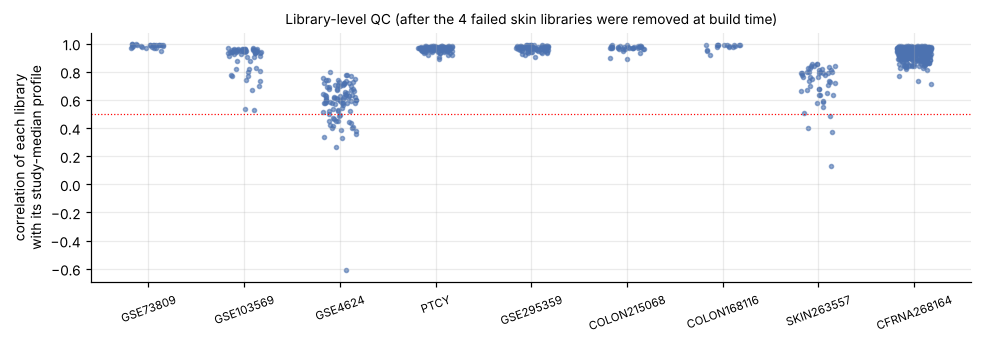

Removed at build time (qc_removed.csv):
     study                              column                                      reason
SKIN263557              D05.690_S37...Response every gene equals log2(1e-5): empty library
SKIN263557 AAZ.042._D13.1401_S52...No_Response every gene equals log2(1e-5): empty library
SKIN263557              D19.4180_S28...Control every gene equals log2(1e-5): empty library
SKIN263557              D19.4661_S13...Control every gene equals log2(1e-5): empty library


,samples,zero-variance libraries,min r to study-median profile,5th pct r,libraries with r < 0.5
study,,,,,
GSE73809,24,0,0.95,0.97,0
GSE103569,60,0,0.53,0.70,0
GSE4624,96,0,-0.61,0.37,22
PTCY,101,0,0.89,0.93,0
GSE295359,75,0,0.90,0.93,0
COLON215068,33,0,0.89,0.92,0
COLON168116,17,0,0.92,0.94,0
SKIN263557,50,0,0.13,0.44,4
CFRNA268164,382,0,0.71,0.85,0


In [11]:
# ---------------------------------------------------------------- QC audit of the bundle (this audit is what found the failed skin libraries)
qc_removed = pd.read_csv(os.path.join(DATA_DIR, 'qc_removed.csv'))
rows, cors = [], {}
for st, r in RAW.items():
    X = r['X'][:, np.isfinite(r['X']).any(0)]; Xf = np.nan_to_num(X); med = np.nanmedian(X, 0)
    cr = np.array([np.corrcoef(Xf[i], med)[0, 1] for i in range(len(Xf))]); cors[st] = cr
    rows.append(dict(study=st, samples=len(Xf), **{'zero-variance libraries': int((np.nanstd(X, 1) < 1e-9).sum()), 'min r to study-median profile': round(float(np.nanmin(cr)), 2),
                     '5th pct r': round(float(np.nanpercentile(cr, 5)), 2), 'libraries with r < 0.5': int((cr < .5).sum())}))
qc = pd.DataFrame(rows).set_index('study')
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (st, cr) in enumerate(cors.items()):
    ax.scatter(np.full(len(cr), i) + np.random.default_rng(i).uniform(-.18, .18, len(cr)), cr, s=7, alpha=.6, color='#4C72B0')
ax.axhline(.5, color='r', lw=.8, ls=':'); ax.set_xticks(range(len(cors))); ax.set_xticklabels(list(cors), rotation=20, fontsize=7.5); ax.set_ylabel('correlation of each library\nwith its study-median profile')
ax.set_title('Library-level QC (after the 4 failed skin libraries were removed at build time)', fontsize=9); plt.tight_layout(); plt.show()
print('Removed at build time (qc_removed.csv):'); print(qc_removed.to_string(index=False)); qc

**QC findings.** (1) In GSE263557 (skin), **4 of 54 libraries are empty** — every gene sits at the matrix's zero floor (log₂ 10⁻⁵) — including **2 of the 9 control biopsies**. They were removed at build time (`qc_removed.csv`) and the matrix was converted to log₂(FPKM+1) to match the colon studies. The effect on headline AUROCs was small, but only **7 control skin samples remain**, which is why every skin CI in this notebook is wide, and any earlier skin figure (including the cross-organ transfer in the evidence ledger) should be read with that in mind. (2) GSE4624 has heterogeneous library quality (22 of 96 libraries correlate < 0.5 with the study-median profile). They are **kept** — unlike the empty skin libraries there is no objective failure criterion — but its prognostic tasks (P1, P2) are interpreted with that in mind. (3) No duplicated profiles were found in any study.

> **Reading guide for Part E.** Numbers in the grey result lines below are *computed from the variables above them*, so they cannot drift from the code. The interpretive sentences were written for the full run (`QUICK=False`); if you switch to `QUICK=True` the numbers move and some interpretation may no longer hold.

## E.2 Leave-one-study-out (LOSO): the pre-stated 7-study benchmark
Train a patient-grouped ridge-logistic head on six studies; score the seventh. Three designs (D.4). Features are z-scored within study × compartment **without labels**. Study order is by platform and sample type. Each bar's whisker is a 95 % patient-bootstrap CI — and with 17–88 patients per held-out study these are **wide**: treat differences below ~0.1 AUROC between arms as unresolved *within a single study*; the across-study mean is the more informative summary.

In [12]:
# ---------------------------------------------------------------- PRE-STATED 7-STUDY LEAVE-ONE-STUDY-OUT BENCHMARK
DIAG = ['GSE73809', 'GSE103569', 'PTCY', 'GSE295359', 'COLON215068', 'COLON168116', 'SKIN263557']      # label = "GVHD present in the sample's patient at sampling"
TISSUE = {'COLON215068', 'COLON168116', 'SKIN263557'}

def diag_rows(name):
    m = RAW[name]['meta']; keep = np.ones(len(m), bool)
    if name == 'GSE295359': keep = m.timepoint.isin(['D30', 'D100']).to_numpy()          # concurrent-GVHD semantics only (not pre-transplant graft)
    if name == 'PTCY': keep &= (m.block != 'NK').to_numpy()                              # NK cells carry no GVHD label semantics here
    return keep

POOL = {n: featurize(n, diag_rows(n)) for n in DIAG}
stu = np.concatenate([[n] * len(POOL[n]['meta']) for n in DIAG])
y_all = np.concatenate([POOL[n]['meta'].y.to_numpy().astype(int) for n in DIAG])
pat_all = np.concatenate([[f'{n}:{p}' for p in POOL[n]['meta'].patient.astype(str)] for n in DIAG])
tissue_ind = np.concatenate([[float(n in TISSUE)] * len(POOL[n]['meta']) for n in DIAG])
G_all = np.vstack([POOL[n]['G'] for n in DIAG]); H_all = np.vstack([POOL[n]['H'] for n in DIAG])
print(pd.DataFrame({n: dict(samples=len(POOL[n]['meta']), patients=POOL[n]['meta'].patient.nunique(), positives=int(POOL[n]['meta'].y.sum()),
                            prevalence=round(POOL[n]['meta'].y.mean(), 2), context='tissue' if n in TISSUE else 'blood/T-cell') for n in DIAG}).T.to_string())

def design(kind, H=None):
    H = H_all if H is None else H
    if kind == 'genes': return G_all
    if kind == 'path50': return H
    if kind == 'moe50': return np.hstack([H, H * tissue_ind[:, None]])          # shared head + tissue-specific expert (both L2-penalised)
    raise KeyError(kind)

def loso(X, held_list=DIAG, boot=1000):
    out = {}
    for held in held_list:
        tr, te = stu != held, stu == held
        head, C = fit_head(X[tr], y_all[tr], pat_all[tr], seed=3)
        s = head.decision_function(X[te])
        lo = hi = float('nan')
        if boot:
            lo, hi = ci95(group_bootstrap_auc(y_all[te], [s], pat_all[te], boot, seed=5)[0])
        out[held] = dict(auroc=auroc(y_all[te], s), lo=lo, hi=hi, C=C, n=int(te.sum()), score=s)
    return out

t0 = time.time()
LOSO = {k: loso(design(k)) for k in ('genes', 'path50', 'moe50')}
print(f'LOSO done in {time.time() - t0:.0f}s')
tab = pd.DataFrame({k: {h: v[h]['auroc'] for h in DIAG} for k, v in LOSO.items()}).round(3)
tab.loc['MEAN'] = tab.mean().round(3); tab.loc['studies > 0.60'] = [(tab.loc[DIAG, c] > 0.6).sum() for c in tab.columns]
tab

            samples patients positives prevalence       context
GSE73809         24       24        11       0.46  blood/T-cell
GSE103569        60       20        45       0.75  blood/T-cell
PTCY             88       88        38       0.43  blood/T-cell
GSE295359        48       10        24        0.5  blood/T-cell
COLON215068      33       33        18       0.55        tissue
COLON168116      17       17         9       0.53        tissue
SKIN263557       50       50        43       0.86        tissue


LOSO done in 186s


,genes,path50,moe50
GSE73809,0.790,0.860,0.811
GSE103569,0.413,0.464,0.496
PTCY,0.577,0.466,0.595
GSE295359,0.595,0.538,0.495
COLON215068,0.826,0.748,0.652
COLON168116,0.833,0.694,0.722
SKIN263557,0.754,0.355,0.488
MEAN,0.684,0.589,0.608
studies > 0.60,4.000,3.000,3.000


## E.3 Controls and the pre-stated gate
Two controls bound what "a 50-dimensional head" can achieve by accident: **(i)** 50 *shuffled-membership* pathways (same set sizes, random genes from the Hallmark universe), **(ii)** 50 *random projections* of the 3,072 genes. Then the gate from D.4 is applied exactly as written.

In [13]:
# ---------------------------------------------------------------- CONTROLS for the pathway arm, then the PRE-STATED GATE
# (1) shuffled-membership control: same 50 set sizes, random genes drawn from the same universe of Hallmark members
# (2) random-projection control: 3,072 genes -> 50 random linear combinations (is "50 dimensions" alone what helps?)
universe = sorted({g for v in HALLMARK.values() for g in v if g in kpos})
sizes = [len(HALLMARK[n]) for n in HNAMES]
rng = np.random.default_rng(1)
shuf = []
for rep in range(N_CONTROL):
    sets = {n: list(rng.choice(universe, size=s, replace=False)) for n, s in zip(HNAMES, sizes)}
    Hs = np.vstack([hallmark_scores(POOL[d]['Z'], POOL[d]['measured'], sets=sets, names=HNAMES) for d in DIAG])
    r = loso(design('path50', Hs), boot=0)
    shuf.append({d: r[d]['auroc'] for d in DIAG})
shuf = pd.DataFrame(shuf)
rproj = []
for rep in range(N_CONTROL):
    R = np.random.default_rng(100 + rep).standard_normal((G_all.shape[1], 50)) / np.sqrt(G_all.shape[1])
    r = loso(G_all @ R, boot=0)
    rproj.append({d: r[d]['auroc'] for d in DIAG})
rproj = pd.DataFrame(rproj)
print(f'shuffled-pathway control ({N_CONTROL} reps): mean LOSO AUROC {shuf.mean(1).mean():.3f} +/- {shuf.mean(1).std():.3f} (max {shuf.mean(1).max():.3f})')
print(f'random-projection control ({N_CONTROL} reps): mean LOSO AUROC {rproj.mean(1).mean():.3f} +/- {rproj.mean(1).std():.3f} (max {rproj.mean(1).max():.3f})')

# ---------------------------------------------------------------- the gate, exactly as fixed before the run (see GATE text above)
m_genes = np.mean([LOSO['genes'][d]['auroc'] for d in DIAG]); p95 = float(np.quantile(shuf.mean(1), .95))
GATE_ROWS = []
for k in ('path50', 'moe50'):
    m = np.mean([LOSO[k][d]['auroc'] for d in DIAG]); n6 = sum(LOSO[k][d]['auroc'] > .6 for d in DIAG)
    ok = (m >= .70, m >= m_genes + .05, m > p95, n6 >= 5)
    GATE_ROWS.append({'design': k, 'mean LOSO AUROC': round(m, 3), '>= 0.70': ok[0], f'>= genes ({m_genes:.3f}) + 0.05': ok[1],
                      f'> 95th pct of shuffled ({p95:.3f})': ok[2], 'studies > 0.60 (need 5/7)': f'{n6}/7 -> {ok[3]}', 'VERDICT': 'WORKS' if all(ok) else 'NOT PASSED'})
gate_tab = pd.DataFrame(GATE_ROWS).set_index('design'); gate_tab

shuffled-pathway control (20 reps): mean LOSO AUROC 0.623 +/- 0.033 (max 0.694)
random-projection control (20 reps): mean LOSO AUROC 0.608 +/- 0.040 (max 0.669)


,mean LOSO AUROC,>= 0.70,>= genes (0.684) + 0.05,> 95th pct of shuffled (0.672),studies > 0.60 (need 5/7),VERDICT
design,,,,,,
path50,0.589,False,False,False,3/7 -> False,NOT PASSED
moe50,0.608,False,False,False,3/7 -> False,NOT PASSED


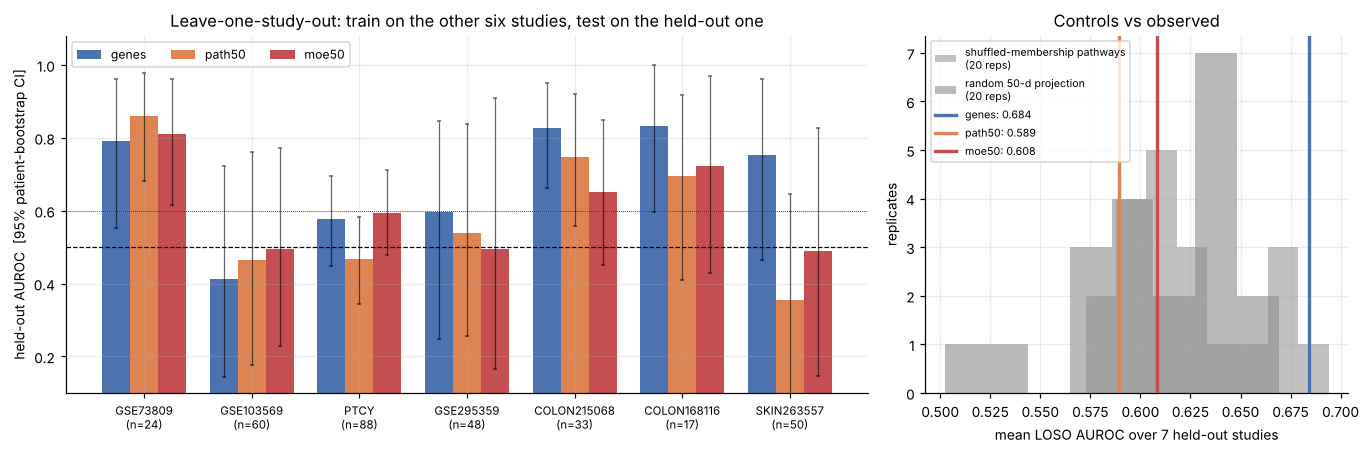

,genes,path50,moe50
GSE73809,"0.79 [0.55,0.96]","0.86 [0.68,0.98]","0.81 [0.61,0.96]"
GSE103569,"0.41 [0.14,0.72]","0.46 [0.18,0.76]","0.50 [0.23,0.77]"
PTCY,"0.58 [0.45,0.69]","0.47 [0.34,0.58]","0.59 [0.48,0.71]"
GSE295359,"0.60 [0.25,0.85]","0.54 [0.26,0.84]","0.49 [0.17,0.91]"
COLON215068,"0.83 [0.66,0.95]","0.75 [0.56,0.92]","0.65 [0.45,0.85]"
COLON168116,"0.83 [0.60,1.00]","0.69 [0.41,0.92]","0.72 [0.43,0.97]"
SKIN263557,"0.75 [0.46,0.96]","0.36 [0.06,0.65]","0.49 [0.15,0.83]"


,genes,path50,moe50
blood / sorted T cells (4 studies),0.594,0.582,0.599
tissue biopsy (3 studies),0.804,0.599,0.621


In [14]:
# ---------------------------------------------------------------- Figure: leave-one-study-out results
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={'width_ratios': [1.9, 1]})
arms = ['genes', 'path50', 'moe50']; w = 0.26; xs = np.arange(len(DIAG))
for i, a in enumerate(arms):
    v = np.array([LOSO[a][d]['auroc'] for d in DIAG]); lo = np.array([LOSO[a][d]['lo'] for d in DIAG]); hi = np.array([LOSO[a][d]['hi'] for d in DIAG])
    ax[0].bar(xs + (i - 1) * w, v, w, color=ARM_COLORS[a], label=a, yerr=[v - lo, hi - v], error_kw=dict(lw=.8, capsize=1.5, alpha=.6))
ax[0].axhline(.5, color='k', lw=.8, ls='--'); ax[0].axhline(.6, color='k', lw=.5, ls=':')
ax[0].set_xticks(xs); ax[0].set_xticklabels([f'{d}\n(n={LOSO["genes"][d]["n"]})' for d in DIAG], fontsize=7.5); ax[0].set_ylim(.1, 1.08)
ax[0].set_ylabel('held-out AUROC  [95% patient-bootstrap CI]'); ax[0].set_title('Leave-one-study-out: train on the other six studies, test on the held-out one'); ax[0].legend(ncol=3, fontsize=8, loc='upper left')
means = {a: np.mean([LOSO[a][d]['auroc'] for d in DIAG]) for a in arms}
ax[1].hist(shuf.mean(1), bins=8, color=ARM_COLORS['shuf50'], alpha=.9, label=f'shuffled-membership pathways\n({N_CONTROL} reps)')
ax[1].hist(rproj.mean(1), bins=8, color=ARM_COLORS['rand50'], alpha=.6, label=f'random 50-d projection\n({N_CONTROL} reps)')
for a in arms: ax[1].axvline(means[a], color=ARM_COLORS[a], lw=2.2, label=f'{a}: {means[a]:.3f}')
ax[1].set_xlabel('mean LOSO AUROC over 7 held-out studies'); ax[1].set_ylabel('replicates'); ax[1].set_title('Controls vs observed'); ax[1].legend(fontsize=7, loc='upper left')
plt.tight_layout(); plt.show()
loso_tab = pd.DataFrame({a: {d: f"{LOSO[a][d]['auroc']:.2f} [{LOSO[a][d]['lo']:.2f},{LOSO[a][d]['hi']:.2f}]" for d in DIAG} for a in arms})
ctx_tab = pd.DataFrame({a: {'blood / sorted T cells (4 studies)': np.mean([LOSO[a][d]['auroc'] for d in DIAG if d not in TISSUE]),
                            'tissue biopsy (3 studies)': np.mean([LOSO[a][d]['auroc'] for d in DIAG if d in TISSUE])} for a in arms}).round(3)
display(loso_tab); display(ctx_tab)

In [15]:
mg, mp, mm = (np.mean([LOSO[a][d]['auroc'] for d in DIAG]) for a in ('genes', 'path50', 'moe50'))
blood = [d for d in DIAG if d not in TISSUE]
display(Markdown(f"""**Result.** Mean LOSO AUROC over 7 held-out studies: **normalized genes {mg:.3f}**, Hallmark-50 pathways **{mp:.3f}**, pathway + tissue expert **{mm:.3f}**.
Genes are above 0.60 in {sum(LOSO['genes'][d]['auroc'] > .6 for d in DIAG)}/7 studies. Split by sample type, genes score **{ctx_tab.loc['tissue biopsy (3 studies)', 'genes']:.2f} on tissue biopsies** (two independent colon cohorts and skin, three labs, two organs) but only **{ctx_tab.loc['blood / sorted T cells (4 studies)', 'genes']:.2f} on blood / sorted T cells**, where three of four studies sit at or below ~0.6 and the CIs include 0.5.
Tissue-biopsy GvHD is a *replicable* signal across labs; blood-T-cell GvHD at sampling is not — at this n."""))

**Result.** Mean LOSO AUROC over 7 held-out studies: **normalized genes 0.684**, Hallmark-50 pathways **0.589**, pathway + tissue expert **0.608**.
Genes are above 0.60 in 4/7 studies. Split by sample type, genes score **0.80 on tissue biopsies** (two independent colon cohorts and skin, three labs, two organs) but only **0.59 on blood / sorted T cells**, where three of four studies sit at or below ~0.6 and the CIs include 0.5.
Tissue-biopsy GvHD is a *replicable* signal across labs; blood-T-cell GvHD at sampling is not — at this n.

In [16]:
display(Markdown(f"""**Result.** Shuffled-membership pathways: mean LOSO **{shuf.mean(1).mean():.3f} ± {shuf.mean(1).std():.3f}** ({N_CONTROL} replicates); random 50-d projection: **{rproj.mean(1).mean():.3f} ± {rproj.mean(1).std():.3f}**. Observed: genes {mg:.3f}, path50 {mp:.3f}, moe50 {mm:.3f}.
**Gate verdicts:** {'; '.join(f"{k} → **{v}**" for k, v in gate_tab['VERDICT'].items())}. The curated Hallmark head is **not distinguishable from — and numerically below — a head built from random gene sets**, and it is below normalized genes in {sum(LOSO['path50'][d]['auroc'] < LOSO['genes'][d]['auroc'] for d in DIAG)} of 7 studies.
**This overturns the earlier exploratory claim** (pathway prior 0.695 vs genes 0.615 on four studies): that gap was real *in that setting* (E.4), but it does not survive the pre-stated seven-study test."""))

**Result.** Shuffled-membership pathways: mean LOSO **0.623 ± 0.033** (20 replicates); random 50-d projection: **0.608 ± 0.040**. Observed: genes 0.684, path50 0.589, moe50 0.608.
**Gate verdicts:** path50 → **NOT PASSED**; moe50 → **NOT PASSED**. The curated Hallmark head is **not distinguishable from — and numerically below — a head built from random gene sets**, and it is below normalized genes in 5 of 7 studies.
**This overturns the earlier exploratory claim** (pathway prior 0.695 vs genes 0.615 on four studies): that gap was real *in that setting* (E.4), but it does not survive the pre-stated seven-study test.

## E.4 Why did the earlier result flip? Training-set sensitivity
The earlier claim came from four blood / sorted-T-cell studies, training on the other three. Two follow-ups with everything else fixed: **(a)** drop one *additional* training study each time; **(b)** re-create the original four-study setting inside this benchmark.

(a) AUROC range over the 6 "drop one more training study" refits (fixed C = median selected C):
              mean           min           max       
arm          genes path50  genes path50  genes path50
held                                                 
COLON168116  0.815  0.669  0.736  0.569  0.861  0.750
COLON215068  0.809  0.764  0.737  0.663  0.852  0.826
GSE103569    0.407  0.458  0.342  0.393  0.446  0.538
GSE295359    0.606  0.569  0.507  0.408  0.793  0.861
GSE73809     0.779  0.790  0.685  0.678  0.846  0.867
PTCY         0.573  0.498  0.455  0.451  0.640  0.562
SKIN263557   0.764  0.372  0.714  0.206  0.807  0.571

(b) original four-study exploratory setting (train on the other three blood/T-cell studies only):
        GSE73809  GSE103569   PTCY  GSE295359   mean
genes      0.727      0.529  0.592      0.566  0.603
path50     0.867      0.637  0.620      0.622  0.686


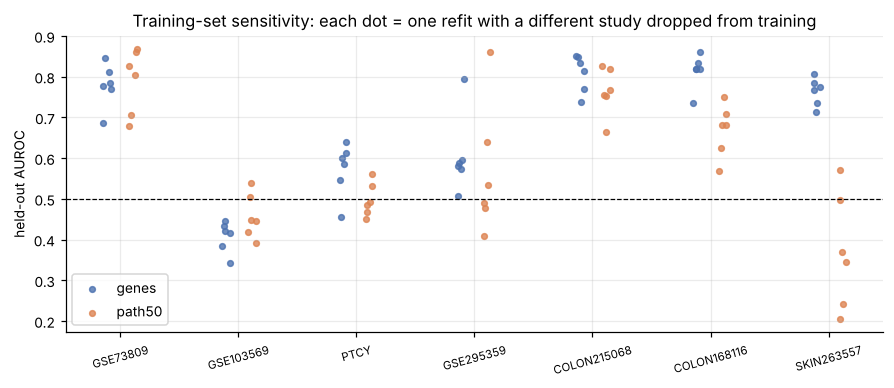

In [17]:
# ---------------------------------------------------------------- Is the ranking of designs stable, or an accident of which studies sit in the training set?
# (a) "drop one more": for each held-out study h and each other study d, train on everything except {h, d}
# (b) the ORIGINAL exploratory setting: the four blood/T-cell studies only (train on the other three)
def med_C(a): return float(np.median([LOSO[a][d]['C'] for d in DIAG]))
FIXED_C = {a: med_C(a) for a in ('genes', 'path50')}
def auc_subset(X, a, held, train_studies):
    tr = np.isin(stu, train_studies); te = stu == held
    s = make_head(FIXED_C[a]).fit(X[tr], y_all[tr]).decision_function(X[te]); return auroc(y_all[te], s)
Xs = {'genes': design('genes'), 'path50': design('path50')}
rows = []
for a in ('genes', 'path50'):
    for h in DIAG:
        others = [d for d in DIAG if d != h]
        for d in others:
            rows.append(dict(arm=a, held=h, dropped=d, auroc=auc_subset(Xs[a], a, h, [o for o in others if o != d])))
sens = pd.DataFrame(rows)
ORIG4 = ['GSE73809', 'GSE103569', 'PTCY', 'GSE295359']
orig = {a: {h: auc_subset(Xs[a], a, h, [o for o in ORIG4 if o != h]) for h in ORIG4} for a in ('genes', 'path50')}
sens_sum = sens.groupby(['arm', 'held']).auroc.agg(['mean', 'min', 'max']).round(3).unstack(0)
print('(a) AUROC range over the 6 "drop one more training study" refits (fixed C = median selected C):'); print(sens_sum.to_string())
print('\n(b) original four-study exploratory setting (train on the other three blood/T-cell studies only):')
print(pd.DataFrame(orig).assign(**{}).round(3).T.assign(mean=lambda d: d.mean(1).round(3)).to_string())
fig, ax = plt.subplots(figsize=(8.2, 3.6))
for i, a in enumerate(('genes', 'path50')):
    for j, h in enumerate(DIAG):
        v = sens[(sens.arm == a) & (sens.held == h)].auroc.to_numpy()
        ax.scatter(np.full(len(v), j + (i - .5) * .22) + np.random.default_rng(j).uniform(-.04, .04, len(v)), v, s=14, color=ARM_COLORS[a], alpha=.8, label=a if j == 0 else None)
ax.axhline(.5, color='k', lw=.8, ls='--'); ax.set_xticks(range(len(DIAG))); ax.set_xticklabels(DIAG, fontsize=7.5, rotation=15)
ax.set_ylabel('held-out AUROC'); ax.set_title('Training-set sensitivity: each dot = one refit with a different study dropped from training'); ax.legend(); plt.tight_layout(); plt.show()

In [18]:
o_g, o_p = np.mean(list(orig['genes'].values())), np.mean(list(orig['path50'].values()))
n_g = np.mean([LOSO['genes'][d]['auroc'] for d in ORIG4]); n_p = np.mean([LOSO['path50'][d]['auroc'] for d in ORIG4])
span = sens.groupby(['arm', 'held']).auroc.agg(lambda v: v.max() - v.min()).unstack(0)
display(Markdown(f"""**Result.** (b) Training on the other three blood/T-cell studies only reproduces the earlier pattern: pathways **{o_p:.3f}** vs genes **{o_g:.3f}** (mean over the same four held-out studies). With all six other studies in training — adding the three tissue studies — the *same four* held-out studies score pathways **{n_p:.3f}** vs genes **{n_g:.3f}**: the pathway advantage is gone, and it is the pathway head that loses (PtCy {orig['path50']['PTCY']:.2f} → {LOSO['path50']['PTCY']['auroc']:.2f}).
(a) Dropping a single training study moves a held-out AUROC by up to **{span.max().max():.2f}** (median range {span.stack().median():.2f}) — comparable to the differences between arms.
**Reading.** A single linear head over pathway scores cannot serve both inflamed tissue and sorted blood T cells (the tissue studies are 53–86 % positive and dominated by an IFN/cytotoxic programme that blood T cells don't show — consistent with E.8, where the IFN-γ / allograft scores work in tissue but not in PtCy T cells); adding the tissue-expert term (moe50) did not repair it. Conclusions about "which feature space transfers" drawn from three or four studies are **fragile**, which is itself an argument for benchmarking at ≥ 10 studies (Part F)."""))

**Result.** (b) Training on the other three blood/T-cell studies only reproduces the earlier pattern: pathways **0.686** vs genes **0.604** (mean over the same four held-out studies). With all six other studies in training — adding the three tissue studies — the *same four* held-out studies score pathways **0.582** vs genes **0.594**: the pathway advantage is gone, and it is the pathway head that loses (PtCy 0.62 → 0.47).
(a) Dropping a single training study moves a held-out AUROC by up to **0.45** (median range 0.16) — comparable to the differences between arms.
**Reading.** A single linear head over pathway scores cannot serve both inflamed tissue and sorted blood T cells (the tissue studies are 53–86 % positive and dominated by an IFN/cytotoxic programme that blood T cells don't show — consistent with E.8, where the IFN-γ / allograft scores work in tissue but not in PtCy T cells); adding the tissue-expert term (moe50) did not repair it. Conclusions about "which feature space transfers" drawn from three or four studies are **fragile**, which is itself an argument for benchmarking at ≥ 10 studies (Part F).

## E.5 Within-study ledger: 16 tasks, patient-grouped repeated CV
Every task gets: out-of-fold AUROC (mean of repeated patient-grouped 5-fold CV) with a **patient-bootstrap CI**, a **permutation null** (labels shuffled across patients, full pipeline re-run), **Benjamini–Hochberg** adjustment across the 16 tasks, and a **confounder-only** model (batch, library size, array order, site, day post-HCT, library-prep order) as the mandatory comparator. This is the slow cell: results are cached in `benchmark/results/` (set `RECOMPUTE=True` to regenerate).

In [19]:
# ---------------------------------------------------------------- Within-study task ledger: patient-grouped repeated CV, bootstrap CIs, permutation nulls, confounder-only baselines
TASKS = [
 dict(id='P1  donor CD8 -> recipient aGVHD',     study='GSE4624',   where={'block': ['CD8']},               kind='prognostic', conf=['array_order']),
 dict(id='P2  donor CD4 -> recipient aGVHD',     study='GSE4624',   where={'block': ['CD4']},               kind='prognostic', conf=['array_order']),
 dict(id='D1  PtCy CD8 (GVHD at sampling)',      study='PTCY',      where={'block': ['CD8']},               kind='diagnostic', conf=['batch']),
 dict(id='D2  PtCy CD4 Tconv',                   study='PTCY',      where={'block': ['CD4_Tconv']},         kind='diagnostic', conf=['batch']),
 dict(id='D3  PtCy Treg',                        study='PTCY',      where={'block': ['Treg']},              kind='diagnostic', conf=['batch']),
 dict(id='D4  PBMC T cells d28-176',             study='GSE73809',  where={},                               kind='diagnostic', conf=['batch', 'site', 'day_post_hct']),
 dict(id='D5  CD8 subsets (skin/gut-homing)',    study='GSE103569', where={},                               kind='diagnostic', conf=[]),
 dict(id='D6  scRNA pseudobulk D30/D100',        study='GSE295359', where={'timepoint': ['D30', 'D100']},  kind='diagnostic', conf=['timepoint']),
 dict(id='B1  colon biopsy (GSE215068)',         study='COLON215068', where={},                             kind='diagnostic', conf=[]),
 dict(id='B2  colon biopsy (GSE168116)',         study='COLON168116', where={},                             kind='diagnostic', conf=[]),
 dict(id='B3  skin GVHD vs control skin',        study='SKIN263557', where={},                              kind='diagnostic', conf=['libprep_order']),
 dict(id='B4  skin d28 steroid NON-response',    study='SKIN263557', where={'y_nr': 'notna'}, label='y_nr',  kind='prognostic', conf=['libprep_order']),
 dict(id='C1  cfRNA PR+D0 -> ever aGVHD',        study='CFRNA268164', where={'timepoint': ['PR', 'D0']},    kind='prognostic', conf=['batch', 'libsize_log10']),
 dict(id='C2  cfRNA month 1 -> ever aGVHD',      study='CFRNA268164', where={'timepoint': ['1M']},          kind='prognostic', conf=['batch', 'libsize_log10']),
 dict(id='C3  cfRNA month 2',                    study='CFRNA268164', where={'timepoint': ['2M']},          kind='prognostic', conf=['batch', 'libsize_log10']),
 dict(id='C4  cfRNA month 3',                    study='CFRNA268164', where={'timepoint': ['3M']},          kind='prognostic', conf=['batch', 'libsize_log10']),
]
def task_mask(t):
    m = RAW[t['study']]['meta']; keep = np.ones(len(m), bool)
    for col, vals in t['where'].items():
        keep &= m[col].notna().to_numpy() if isinstance(vals, str) else m[col].isin(vals).to_numpy()
    return keep

def conf_matrix(meta, cols):
    parts = []
    for c in cols:
        v = meta[c]
        parts.append(pd.get_dummies(v.astype(str)).to_numpy(float) if v.dtype == object else v.to_numpy(float)[:, None])
    return np.hstack(parts)

def evaluate_arm(X, y, g, repeats, n_perm, boot=1000, perm_seed=0, refine=0, refine_p=0.05):
    oofs = [cv_oof(X, y, g, r) for r in range(repeats)]
    a = float(np.mean([auroc(y, o) for o in oofs])); avg = np.nanmean(np.stack(oofs), 0)
    lo, hi = ci95(group_bootstrap_auc(y, [avg], g, boot, seed=5)[0])
    p = float('nan')
    if n_perm:
        null = perm_null(X, y, g, n_perm=n_perm, seed=perm_seed); hits, tot = int((null >= a).sum()), len(null)
        if refine and (1 + hits) / (1 + tot) <= refine_p:          # adaptive Monte-Carlo refinement: only near-significant tests get more permutations
            null2 = perm_null(X, y, g, n_perm=refine, seed=perm_seed + 1000); hits += int((null2 >= a).sum()); tot += len(null2)
        p = float((1 + hits) / (1 + tot))
    return dict(auroc=a, lo=lo, hi=hi, p=p, n_perm_used=int(tot) if n_perm else 0, oof=avg)

def run_task(t):
    warnings.simplefilter('ignore')
    keep = task_mask(t); F = featurize(t['study'], keep); m = F['meta']
    y = m[t.get('label', 'y')].to_numpy().astype(int); g = m.patient.astype(str).to_numpy()
    row = dict(task=t['id'], kind=t['kind'], study=t['study'], n=len(y), patients=len(set(g)), pos=int(y.sum()))
    for arm, X in (('genes', F['G']), ('path50', F['H'])):
        r = evaluate_arm(X, y, g, REPEATS, N_PERM, perm_seed=11, refine=N_REFINE); r.pop('oof'); row[arm] = r
    if t['conf']:
        Xc = conf_matrix(m, t['conf']); row['confounder'] = float(np.mean([auroc(y, cv_oof(Xc, y, g, r)) for r in range(REPEATS)])); row['conf_vars'] = ','.join(t['conf'])
    return row
LEDGER = cached('within_study_ledger', lambda: Parallel(n_jobs=N_JOBS)(delayed(run_task)(t) for t in TASKS))
led = pd.DataFrame([{**{k: v for k, v in r.items() if k not in ('genes', 'path50')},
                     **{f'{a}_auroc': r[a]['auroc'] for a in ('genes', 'path50')}, **{f'{a}_lo': r[a]['lo'] for a in ('genes', 'path50')},
                     **{f'{a}_hi': r[a]['hi'] for a in ('genes', 'path50')}, **{f'{a}_p': r[a]['p'] for a in ('genes', 'path50')}} for r in LEDGER])
for a in ('genes', 'path50'):
    led[f'{a}_q'] = bh_adjust(led[f'{a}_p'].fillna(1).to_numpy())
led['confounded?'] = np.where(led.confounder.notna() & (led.confounder >= led.genes_auroc - 0.05), 'CONFOUNDER-ONLY ~ GENES', '')
led_show = led[['task', 'kind', 'n', 'patients', 'pos', 'genes_auroc', 'genes_lo', 'genes_hi', 'genes_p', 'genes_q', 'path50_auroc', 'path50_p', 'path50_q', 'confounder', 'confounded?']].round(3)
led_show

[cache] within_study_ledger.json  (computed 2026-10-24 02:37, 2679s, repeats=4, perms=100)

,task,kind,n,patients,pos,genes_auroc,genes_lo,genes_hi,genes_p,genes_q,path50_auroc,path50_p,path50_q,confounder,confounded?
0,P1 donor CD8 -> recipient aGVHD,prognostic,47,47,18,0.632,0.469,0.790,0.079,0.141,0.729,0.022,0.060,0.664,CONFOUNDER-ONLY ~ GENES
1,P2 donor CD4 -> recipient aGVHD,prognostic,49,49,19,0.532,0.389,0.742,0.317,0.461,0.606,0.168,0.337,0.605,CONFOUNDER-ONLY ~ GENES
2,D1 PtCy CD8 (GVHD at sampling),diagnostic,35,35,14,0.802,0.695,0.953,0.020,0.060,0.611,0.218,0.364,0.436,
3,D2 PtCy CD4 Tconv,diagnostic,33,33,15,0.813,0.667,1.000,0.005,0.040,0.757,0.015,0.056,0.432,
4,D3 PtCy Treg,diagnostic,20,20,9,0.803,0.566,0.979,0.027,0.063,0.669,0.168,0.337,0.338,
5,D4 PBMC T cells d28-176,diagnostic,24,24,11,0.813,0.590,0.963,0.022,0.060,0.869,0.002,0.020,0.378,
6,D5 CD8 subsets (skin/gut-homing),diagnostic,60,20,45,0.479,0.223,0.737,0.535,0.713,0.438,0.634,0.676,NaN,
7,D6 scRNA pseudobulk D30/D100,diagnostic,48,10,24,0.434,0.209,0.701,0.614,0.756,0.578,0.327,0.436,0.281,
8,B1 colon biopsy (GSE215068),diagnostic,33,33,18,0.899,0.778,1.000,0.002,0.040,0.861,0.002,0.020,NaN,
9,B2 colon biopsy (GSE168116),diagnostic,17,17,9,0.660,0.333,0.929,0.248,0.396,0.642,0.287,0.418,NaN,


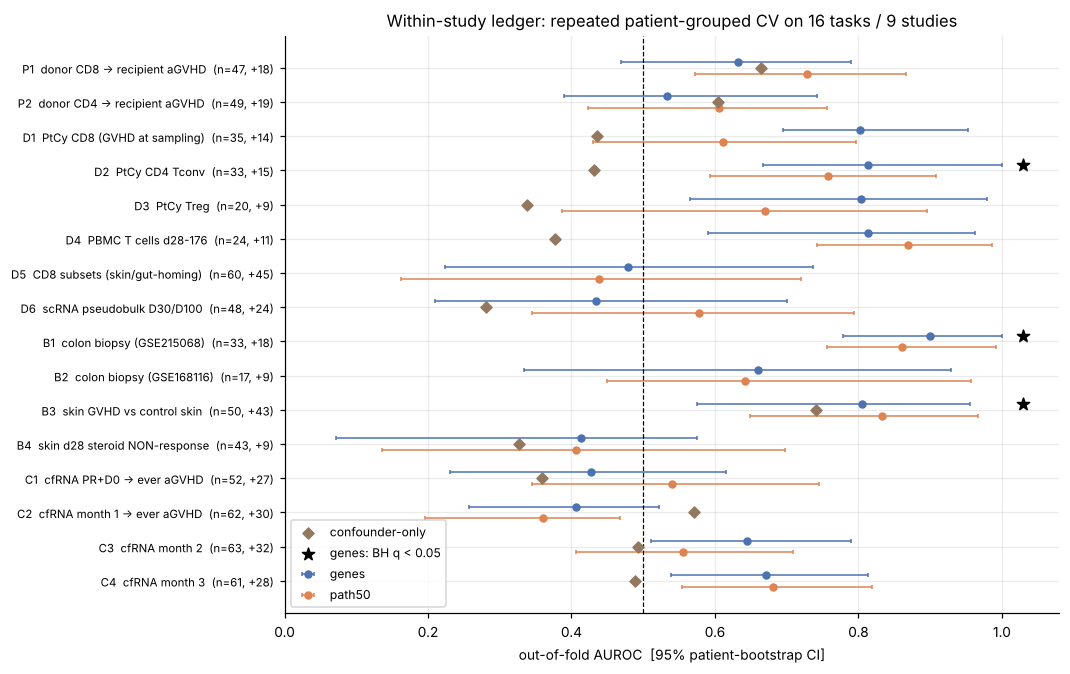

permutations per test: 100 (+300 for tests with p <= 0.05, adaptive refinement); smallest attainable p = 0.0025
genes arm: 3/16 tasks with BH q < 0.05;  path50: 3/16;  tasks where a confounder-only model is within 0.05 of genes: 3


In [20]:
# ---------------------------------------------------------------- Figure: within-study ledger
fig, ax = plt.subplots(figsize=(9.8, 6.2)); yy = np.arange(len(led))[::-1]
for i, (a, off) in enumerate((('genes', .17), ('path50', -.17))):
    ax.errorbar(led[f'{a}_auroc'], yy + off, xerr=[led[f'{a}_auroc'] - led[f'{a}_lo'], led[f'{a}_hi'] - led[f'{a}_auroc']], fmt='o', ms=4.5, lw=1,
                color=ARM_COLORS[a], label=a, capsize=1.5)
ax.scatter(led.confounder, yy, marker='D', s=26, color=ARM_COLORS['clin/conf'], zorder=5, label='confounder-only')
sig = led.genes_q < .05
ax.scatter(np.full(sig.sum(), 1.03), yy[sig.to_numpy()] + .17, marker='*', s=70, color='k', label='genes: BH q < 0.05'); ax.axvline(.5, color='k', lw=.8, ls='--')
ax.set_yticks(yy); ax.set_yticklabels([f"{r.task}  (n={r.n}, +{r.pos})" for r in led.itertuples()], fontsize=7.5); ax.set_xlim(0, 1.08); ax.set_xlabel('out-of-fold AUROC  [95% patient-bootstrap CI]')
ax.set_title('Within-study ledger: repeated patient-grouped CV on 16 tasks / 9 studies'); ax.legend(fontsize=8, loc='lower left'); plt.tight_layout(); plt.show()
n_sig = int((led.genes_q < .05).sum()); print(f'permutations per test: {N_PERM} (+{N_REFINE} for tests with p <= 0.05, adaptive refinement); smallest attainable p = {1/(1+N_PERM+N_REFINE):.4f}')
print(f'genes arm: {n_sig}/{len(led)} tasks with BH q < 0.05;  path50: {(led.path50_q < .05).sum()}/{len(led)};  tasks where a confounder-only model is within 0.05 of genes: {(led["confounded?"] != "").sum()}')

In [21]:
def GA(prefix, col='genes_auroc'): return float(led[led.task.str.startswith(prefix)][col].iloc[0])
supported = led[led.genes_p <= .05].task.str.slice(0, 2).tolist(); none_ = led[(led.genes_p > .2)].task.str.slice(0, 2).tolist()
confd = led[led['confounded?'] != ''].task.str.slice(0, 2).tolist()
display(Markdown(f"""**Result.** {len(supported)} of 16 tasks have a permutation p ≤ 0.05 for the normalized-genes head ({', '.join(supported)}); after Benjamini–Hochberg across the 16 tasks **{int((led.genes_q < .05).sum())} (genes) / {int((led.path50_q < .05).sum())} (pathways) remain below q = 0.05** ({int((led.genes_q < .10).sum())} / {int((led.path50_q < .10).sum())} below q = 0.10). Tasks with q < 0.05 — genes: **{', '.join(led[led.genes_q < .05].task.str.slice(0, 2)) or 'none'}**; pathways: **{', '.join(led[led.path50_q < .05].task.str.slice(0, 2)) or 'none'}**. (Tests with p ≤ 0.05 were refined with {N_REFINE} extra permutations, so the smallest attainable p is {1/(1+N_PERM+N_REFINE):.4f}.) B3 is the least trustworthy of these — a library-prep-order model alone reaches {GA('B3', 'confounder'):.2f} and only 7 control samples remain.
**Where the signal is.** Sorted **PtCy T cells** (D1–D3: {GA('D1'):.2f}, {GA('D2'):.2f}, {GA('D3'):.2f}; confounder-only 0.34–0.44), **PBMC T cells** (D4: {GA('D4'):.2f}), **colon biopsy** (B1: {GA('B1'):.2f}), **skin vs control** (B3: {GA('B3'):.2f}, but a library-prep-order model alone reaches {GA('B3', 'confounder'):.2f}).
**Where it is not.** Homing subsets (D5 {GA('D5'):.2f}), scRNA pseudobulk (D6 {GA('D6'):.2f}), steroid non-response (B4 {GA('B4'):.2f}; n=43, 9 non-responders), cfRNA before and at month 1 (C1 {GA('C1'):.2f}, C2 {GA('C2'):.2f}); the donor→recipient prognostic tasks (P1 {GA('P1'):.2f}, P2 {GA('P2'):.2f}) are **no better than array order alone** ({GA('P1', 'confounder'):.2f}, {GA('P2', 'confounder'):.2f}). cfRNA months 2–3 ({GA('C3'):.2f}, {GA('C4'):.2f}) are the only pre-onset-labelled hits and are 2 of 4 timepoint tests with patient-level labels whose timing relative to onset is unknown — hypothesis-generating only.
**Pathways vs genes.** Within a single study the 50-d pathway head is competitive (best of the two in {int((led.path50_auroc > led.genes_auroc).sum())}/16 tasks), as expected for a low-variance head at small n — the failure in E.2–E.4 is a *transfer* failure, not a within-study one."""))

**Result.** 7 of 16 tasks have a permutation p ≤ 0.05 for the normalized-genes head (D1, D2, D3, D4, B1, B3, C4); after Benjamini–Hochberg across the 16 tasks **3 (genes) / 3 (pathways) remain below q = 0.05** (7 / 6 below q = 0.10). Tasks with q < 0.05 — genes: **D2, B1, B3**; pathways: **D4, B1, B3**. (Tests with p ≤ 0.05 were refined with 300 extra permutations, so the smallest attainable p is 0.0025.) B3 is the least trustworthy of these — a library-prep-order model alone reaches 0.74 and only 7 control samples remain.
**Where the signal is.** Sorted **PtCy T cells** (D1–D3: 0.80, 0.81, 0.80; confounder-only 0.34–0.44), **PBMC T cells** (D4: 0.81), **colon biopsy** (B1: 0.90), **skin vs control** (B3: 0.81, but a library-prep-order model alone reaches 0.74).
**Where it is not.** Homing subsets (D5 0.48), scRNA pseudobulk (D6 0.43), steroid non-response (B4 0.41; n=43, 9 non-responders), cfRNA before and at month 1 (C1 0.43, C2 0.41); the donor→recipient prognostic tasks (P1 0.63, P2 0.53) are **no better than array order alone** (0.66, 0.60). cfRNA months 2–3 (0.64, 0.67) are the only pre-onset-labelled hits and are 2 of 4 timepoint tests with patient-level labels whose timing relative to onset is unknown — hypothesis-generating only.
**Pathways vs genes.** Within a single study the 50-d pathway head is competitive (best of the two in 7/16 tasks), as expected for a low-variance head at small n — the failure in E.2–E.4 is a *transfer* failure, not a within-study one.

## E.6 Frozen foundation-model arms: Geneformer 10M / 104M / 316M and their random-weight twins
Geneformer expects **single-cell-style counts** (rank-value encoding of the top-2,048 genes by expression ÷ gene median). It can therefore only be applied to the studies with whole-transcriptome RNA-seq: **PtCy (3 sorted populations), the two colon cohorts and skin — 4 of the 9 studies**. The microarray studies (GSE73809, GSE103569, GSE4624) and the 3,072-gene pseudobulk release (GSE295359) were **not embedded**: array intensities and a gene-restricted release change what the tokeniser sees in ways that have not been validated for this model, so any number would not be a fair test of it. That mismatch is itself a first-order finding for any FM aimed at public GvHD data, because much public GvHD expression data are arrays.
Each pretrained network is paired with an **identical-architecture, random-weight twin** embedded the same way; "pretraining helps" means pretrained > twin, *not* pretrained > chance. Embeddings are the mean over gene tokens of the second-to-last layer (fixed before evaluation); heads are the same ridge-logistic as everywhere else.

In [22]:
# ---------------------------------------------------------------- FROZEN foundation-model arms (Geneformer 10M / 104M / 316M) vs random-weight twins
_E = np.load(os.path.join(DATA_DIR, 'geneformer_embeddings.npz'), allow_pickle=False); EMB = {k: _E[k] for k in _E.files}      # plain dict of arrays (picklable for the workers)
FM_STUDIES = ['PTCY', 'COLON215068', 'COLON168116', 'SKIN263557']          # the studies whose input matches Geneformer's (RNA-seq, whole transcriptome)
FM_ARMS = {'gf10': 'gf10__pretrained_l2', 'rand10': 'gf10__random_l2', 'gf104': 'gf104__pretrained_l2', 'rand104': 'gf104__random_l2',
           'gf316': 'gf316__pretrained_l2', 'rand316': 'gf316__random_l2'}
def fm_features(study, rows, arm):
    sid = RAW[study]['meta'].sid.astype(str).to_numpy()[rows]; e_sid = {s: i for i, s in enumerate(EMB[study + '__sid'])}
    E = EMB[f'{study}__{FM_ARMS[arm]}'][[e_sid[s] for s in sid]].astype(float)
    blocks = RAW[study]['meta'].block.astype(str).to_numpy()[rows]
    return zblock(E, blocks)[0]                                              # same label-free per-block z-scoring as every other arm
FM_TASKS = [t for t in TASKS if t['study'] in FM_STUDIES]
def run_fm_task(t):
    warnings.simplefilter('ignore')
    keep = task_mask(t); m = RAW[t['study']]['meta'][keep].reset_index(drop=True)
    y = m[t.get('label', 'y')].to_numpy().astype(int); g = m.patient.astype(str).to_numpy(); row = dict(task=t['id'], n=len(y), pos=int(y.sum()))
    for arm in FM_ARMS:
        res = evaluate_arm(fm_features(t['study'], keep, arm), y, g, REPEATS, N_PERM_FM if arm in ('gf104', 'gf316') else 0, perm_seed=21)
        row[arm] = res['auroc']; row[arm + '_lo'] = res['lo']; row[arm + '_hi'] = res['hi']; row[arm + '_p'] = res['p']
    return row
FM_LED = cached('fm_within_study', lambda: Parallel(n_jobs=N_JOBS)(delayed(run_fm_task)(t) for t in FM_TASKS))
for row in FM_LED:
    base = led[led.task == row['task']].iloc[0]; row['genes'] = base.genes_auroc; row['path50'] = base.path50_auroc
    print(f"{row['task']:40s} genes {row['genes']:.2f} | gf10 {row['gf10']:.2f} rand {row['rand10']:.2f} | gf104 {row['gf104']:.2f} rand {row['rand104']:.2f} | gf316 {row['gf316']:.2f} rand {row['rand316']:.2f}")
fmled = pd.DataFrame(FM_LED)
# --- leave-one-study-out among the four RNA-seq studies (train on the other three)
def pooled_fm(arm):
    return np.vstack([fm_features(d, diag_rows(d), arm) for d in FM_STUDIES])
fm_stu = np.concatenate([[d] * int(diag_rows(d).sum()) for d in FM_STUDIES])
fm_y = np.concatenate([RAW[d]['meta'].y.to_numpy()[diag_rows(d)].astype(int) for d in FM_STUDIES])
fm_pat = np.concatenate([[f'{d}:{p}' for p in RAW[d]['meta'].patient.astype(str).to_numpy()[diag_rows(d)]] for d in FM_STUDIES])
fm_G = np.vstack([POOL[d]['G'] for d in FM_STUDIES]); fm_H = np.vstack([POOL[d]['H'] for d in FM_STUDIES])
def loso4(X):
    out = {}
    for held in FM_STUDIES:
        tr, te = fm_stu != held, fm_stu == held
        head, C = fit_head(X[tr], fm_y[tr], fm_pat[tr], seed=3); s = head.decision_function(X[te])
        lo, hi = ci95(group_bootstrap_auc(fm_y[te], [s], fm_pat[te], 1000, seed=5)[0]); out[held] = dict(auroc=auroc(fm_y[te], s), lo=lo, hi=hi)
    return out
LOSO4 = {'genes': loso4(fm_G), 'path50': loso4(fm_H)}
for arm in FM_ARMS: LOSO4[arm] = loso4(pooled_fm(arm))
loso4_tab = pd.DataFrame({a: {d: v[d]['auroc'] for d in FM_STUDIES} for a, v in LOSO4.items()}).round(3)
loso4_tab.loc['MEAN'] = loso4_tab.mean().round(3); loso4_tab

[cache] fm_within_study.json  (computed 2026-10-24 01:28, 233s, repeats=4, perms=100)
D1  PtCy CD8 (GVHD at sampling)          genes 0.80 | gf10 0.46 rand 0.79 | gf104 0.74 rand 0.49 | gf316 0.75 rand 0.51
D2  PtCy CD4 Tconv                       genes 0.81 | gf10 0.47 rand 0.64 | gf104 0.78 rand 0.68 | gf316 0.79 rand 0.52
D3  PtCy Treg                            genes 0.80 | gf10 0.56 rand 0.55 | gf104 0.71 rand 0.79 | gf316 0.67 rand 0.94
B1  colon biopsy (GSE215068)             genes 0.90 | gf10 0.66 rand 0.87 | gf104 0.85 rand 0.77 | gf316 0.85 rand 0.79
B2  colon biopsy (GSE168116)             genes 0.66 | gf10 0.61 rand 0.67 | gf104 0.74 rand 0.62 | gf316 0.65 rand 0.79
B3  skin GVHD vs control skin            genes 0.81 | gf10 0.49 rand 0.75 | gf104 0.73 rand 0.91 | gf316 0.73 rand 0.57
B4  skin d28 steroid NON-response        genes 0.41 | gf10 0.45 rand 0.41 | gf104 0.36 rand 0.41 | gf316 0.32 rand 0.44


,genes,path50,gf10,rand10,gf104,rand104,gf316,rand316
PTCY,0.598,0.557,0.529,0.487,0.585,0.464,0.567,0.615
COLON215068,0.848,0.681,0.548,0.596,0.763,0.707,0.822,0.785
COLON168116,0.833,0.569,0.611,0.625,0.764,0.736,0.639,0.694
SKIN263557,0.744,0.525,0.306,0.482,0.601,0.551,0.432,0.512
MEAN,0.756,0.583,0.498,0.548,0.678,0.614,0.615,0.652


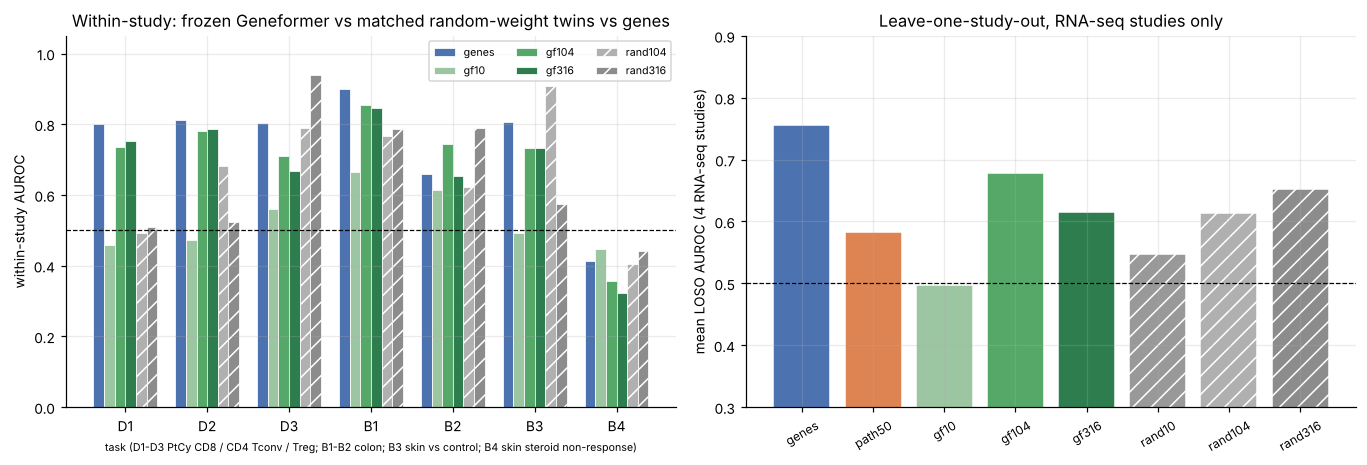

pretrained > random-weight twin in 10 of 21 task x model pairs; any FM arm > genes in 2 of 21


,task,n,pos,genes,path50,gf10,rand10,gf104,rand104,gf316,rand316
0,D1 PtCy CD8 (GVHD at sampling),35,14,0.80,0.61,0.46,0.79,0.74,0.49,0.75,0.51
1,D2 PtCy CD4 Tconv,33,15,0.81,0.76,0.47,0.64,0.78,0.68,0.79,0.52
2,D3 PtCy Treg,20,9,0.80,0.67,0.56,0.55,0.71,0.79,0.67,0.94
3,B1 colon biopsy (GSE215068),33,18,0.90,0.86,0.66,0.87,0.85,0.77,0.85,0.79
4,B2 colon biopsy (GSE168116),17,9,0.66,0.64,0.61,0.67,0.74,0.62,0.65,0.79
5,B3 skin GVHD vs control skin,50,43,0.81,0.83,0.49,0.75,0.73,0.91,0.73,0.57
6,B4 skin d28 steroid NON-response,43,9,0.41,0.41,0.45,0.41,0.36,0.41,0.32,0.44


In [23]:
# ---------------------------------------------------------------- Figure: do pretrained weights beat random weights, and do either beat genes?
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
tasks = fmled.task.tolist(); xs = np.arange(len(tasks)); order = ['genes', 'gf10', 'gf104', 'gf316', 'rand104', 'rand316']; w = .13
for i, a in enumerate(order):
    v = fmled[a].to_numpy(); ax[0].bar(xs + (i - 2.5) * w, v, w, color=ARM_COLORS[a], label=a, hatch='//' if a.startswith('rand') else None, edgecolor='white', lw=.5)
ax[0].axhline(.5, color='k', lw=.8, ls='--'); ax[0].set_xticks(xs); ax[0].set_xticklabels([t[:2] for t in tasks], fontsize=9); ax[0].set_ylim(0, 1.05)
ax[0].set_xlabel('task (D1-D3 PtCy CD8 / CD4 Tconv / Treg; B1-B2 colon; B3 skin vs control; B4 skin steroid non-response)', fontsize=7); ax[0].set_ylabel('within-study AUROC'); ax[0].set_title('Within-study: frozen Geneformer vs matched random-weight twins vs genes'); ax[0].legend(ncol=3, fontsize=7, loc='upper right')
m4 = loso4_tab.loc['MEAN']; arms4 = ['genes', 'path50', 'gf10', 'gf104', 'gf316', 'rand10', 'rand104', 'rand316']
ax[1].bar(range(len(arms4)), [m4[a] for a in arms4], color=[ARM_COLORS.get(a, '#999') for a in arms4], hatch=['//' if a.startswith('rand') else None for a in arms4], edgecolor='white')
ax[1].axhline(.5, color='k', lw=.8, ls='--'); ax[1].set_xticks(range(len(arms4))); ax[1].set_xticklabels(arms4, rotation=30, fontsize=8); ax[1].set_ylim(.3, .9)
ax[1].set_ylabel('mean LOSO AUROC (4 RNA-seq studies)'); ax[1].set_title('Leave-one-study-out, RNA-seq studies only')
plt.tight_layout(); plt.show()
print('pretrained > random-weight twin in', int(sum(fmled[a] > fmled['rand' + a[2:]] for a in ('gf10', 'gf104', 'gf316')).sum()), 'of', 3 * len(fmled), 'task x model pairs; any FM arm > genes in',
      int(sum((fmled[a] > fmled['genes']).sum() for a in ('gf10', 'gf104', 'gf316'))), 'of', 3 * len(fmled))
fmled.round(2)[['task', 'n', 'pos', 'genes', 'path50', 'gf10', 'rand10', 'gf104', 'rand104', 'gf316', 'rand316']]

In [24]:
l4 = loso4_tab.loc['MEAN']; pairs = 3 * len(fmled)
better = int(sum((fmled[a] > fmled['rand' + a[2:]]).sum() for a in ('gf10', 'gf104', 'gf316'))); beat_genes = int(sum((fmled[a] > fmled['genes']).sum() for a in ('gf10', 'gf104', 'gf316')))
def twin(a):
    v = [LOSO4[a][d]['auroc'] for d in FM_STUDIES]; w = [LOSO4['rand' + a[2:]][d]['auroc'] for d in FM_STUDIES]; m_, lo_, hi_ = boot_delta(v, w); return f'{m_:+.3f}', f'[{lo_:+.3f}, {hi_:+.3f}]'
t104, t316, t10 = twin('gf104'), twin('gf316'), twin('gf10')
display(Markdown(f"""**Result — within study (7 tasks).** The pretrained network scores higher than its random-weight twin in only **{better} of {pairs}** task × model pairs, and any foundation-model arm beats normalized genes in **{beat_genes} of {pairs}**. The random-weight twins themselves range from 0.3 to 0.94 on these tiny tasks (e.g. PtCy Treg, n=20: 316M twin 0.94, pretrained 0.67): at n ≈ 20–50 a high-dimensional random embedding is a noisy lottery ticket, so single-task comparisons mean little.
**Result — leave-one-study-out among the four RNA-seq studies.** Mean AUROC: normalized genes **{l4['genes']:.3f}**, Hallmark pathways {l4['path50']:.3f}, Geneformer 10M {l4['gf10']:.3f} (twin {l4['rand10']:.3f}), **104M {l4['gf104']:.3f}** (twin {l4['rand104']:.3f}), **316M {l4['gf316']:.3f}** (twin {l4['rand316']:.3f}). Pretraining adds **{t104[0]}** (study-level CI {t104[1]}) over the random twin for 104M, but **{t316[0]}** for 316M and **{t10[0]}** for 10M — and no Geneformer size improves on genes in any of the four held-out studies.
**Reading.** (i) Geneformer-104M carries *some* transferable information (it beats its own random-weight twin in LOSO) but less than plain normalized genes; (ii) a larger model (316M) did not help — consistent with the published finding that scale alone does not drive downstream gains; (iii) an input-compatibility ceiling: array and gene-restricted releases — a large share of public GvHD data — were not embedded. Fine-tuning was not attempted (n ≈ 30–90 per task)."""))

**Result — within study (7 tasks).** The pretrained network scores higher than its random-weight twin in only **10 of 21** task × model pairs, and any foundation-model arm beats normalized genes in **2 of 21**. The random-weight twins themselves range from 0.3 to 0.94 on these tiny tasks (e.g. PtCy Treg, n=20: 316M twin 0.94, pretrained 0.67): at n ≈ 20–50 a high-dimensional random embedding is a noisy lottery ticket, so single-task comparisons mean little.
**Result — leave-one-study-out among the four RNA-seq studies.** Mean AUROC: normalized genes **0.756**, Hallmark pathways 0.583, Geneformer 10M 0.498 (twin 0.548), **104M 0.678** (twin 0.614), **316M 0.615** (twin 0.652). Pretraining adds **+0.064** (study-level CI [+0.035, +0.104]) over the random twin for 104M, but **-0.037** for 316M and **-0.049** for 10M — and no Geneformer size improves on genes in any of the four held-out studies.
**Reading.** (i) Geneformer-104M carries *some* transferable information (it beats its own random-weight twin in LOSO) but less than plain normalized genes; (ii) a larger model (316M) did not help — consistent with the published finding that scale alone does not drive downstream gains; (iii) an input-compatibility ceiling: array and gene-restricted releases — a large share of public GvHD data — were not embedded. Fine-tuning was not attempted (n ≈ 30–90 per task).

## E.7 Zero-shot representation quality (Tier 1) — Kedzierska-style, no head trained
On the PtCy sorted populations: does the *frozen* embedding keep biology (CD8 / CD4 Tconv / Treg, 5-NN leave-one-out accuracy) while discarding the sequencing batch (lower decodability is better)? Representations are compared with highly-variable genes and with the random-weight twins.

In [25]:
# ---------------------------------------------------------------- Zero-shot representation quality (Kedzierska-style): no head is trained on GVHD labels
# PtCy sorted populations: does the embedding separate biology (CD8 / CD4 Tconv / Treg) and NOT the sequencing batch?
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.metrics import silhouette_score
keep = diag_rows('PTCY'); mp = RAW['PTCY']['meta'][keep].reset_index(drop=True)
bio = mp.block.astype(str).to_numpy(); tech = mp.batch.astype(str).to_numpy()
Xraw = RAW['PTCY']['X'][keep]; hvg = np.argsort(-np.nanvar(Xraw, 0))[:2000]
Zs = np.nan_to_num((Xraw[:, vidx] - Xraw[:, vidx].mean(0)) / np.maximum(Xraw[:, vidx].std(0), 1e-6))         # STUDY-level z (a per-compartment z would erase the biology we test for)
reps = {'HVG-2000 (log CPM)': Xraw[:, hvg], 'vocab genes, study-z': Zs}
for a in ('gf10', 'gf104', 'gf316', 'rand104', 'rand316'):
    sid = mp.sid.astype(str).to_numpy(); e_sid = {s: i for i, s in enumerate(EMB['PTCY__sid'])}
    E = EMB[f'PTCY__{FM_ARMS[a]}'][[e_sid[s] for s in sid]].astype(float); reps[a] = (E - E.mean(0)) / np.maximum(E.std(0), 1e-6)
zs_rows = []
for name, X in reps.items():
    P = PCA(n_components=min(30, X.shape[0] - 1), random_state=0).fit_transform(X)
    row = dict(representation=name)
    for lab_name, lab in (('biology (compartment)', bio), ('sequencing batch', tech)):
        pred = cross_val_predict(KNeighborsClassifier(5), P, lab, cv=LeaveOneOut()); row[f'5-NN acc: {lab_name}'] = (pred == lab).mean()
        row[f'silhouette: {lab_name}'] = silhouette_score(P, lab)
    zs_rows.append(row)
zs = pd.DataFrame(zs_rows).set_index('representation').round(2); zs

,5-NN acc: biology (compartment),silhouette: biology (compartment),5-NN acc: sequencing batch,silhouette: sequencing batch
representation,,,,
HVG-2000 (log CPM),0.97,0.15,0.75,0.10
"vocab genes, study-z",0.93,0.06,0.78,0.10
gf10,0.38,-0.02,0.50,0.01
gf104,0.80,0.02,0.78,0.11
gf316,0.95,0.13,0.77,0.09
rand104,0.85,0.03,0.70,0.05
rand316,0.74,0.02,0.68,0.03


In [26]:
b = zs['5-NN acc: biology (compartment)']; tch = zs['5-NN acc: sequencing batch']
display(Markdown(f"""**Result.** Compartment identity (5-NN accuracy): HVG-2000 **{b['HVG-2000 (log CPM)']:.2f}**, vocabulary genes **{b['vocab genes, study-z']:.2f}**, Geneformer 316M **{b['gf316']:.2f}**, 104M **{b['gf104']:.2f}** (random twin {b['rand104']:.2f}), 10M **{b['gf10']:.2f}**. Batch decodability for the best pretrained embedding is **{tch['gf316']:.2f}** vs **{tch['HVG-2000 (log CPM)']:.2f}** for HVG (the lower, the better).
Only the 316M model approaches the plain-gene baselines on biology, and none removes batch better than HVG; the 104M model is *not* better than its random twin. This matches the published zero-shot audits: a pretrained embedding is not automatically a better *bulk-sample* representation than simple gene selection."""))

**Result.** Compartment identity (5-NN accuracy): HVG-2000 **0.97**, vocabulary genes **0.93**, Geneformer 316M **0.95**, 104M **0.80** (random twin 0.85), 10M **0.38**. Batch decodability for the best pretrained embedding is **0.77** vs **0.75** for HVG (the lower, the better).
Only the 316M model approaches the plain-gene baselines on biology, and none removes batch better than HVG; the 104M model is *not* better than its random twin. This matches the published zero-shot audits: a pretrained embedding is not automatically a better *bulk-sample* representation than simple gene selection.

## E.8 Zero-parameter biology panel — no fitting at all
Two scores were written down **before any cohort was examined**: Hallmark *Allograft Rejection* and *Interferon-γ Response* (mean z of member genes; higher = GvHD). A second view asks which of the 50 Hallmark sets keep the same direction across studies, calibrated against what chance would produce (with 7 studies, ~6 of 50 sets are expected to show ≥ 6/7 same-sign by chance alone).

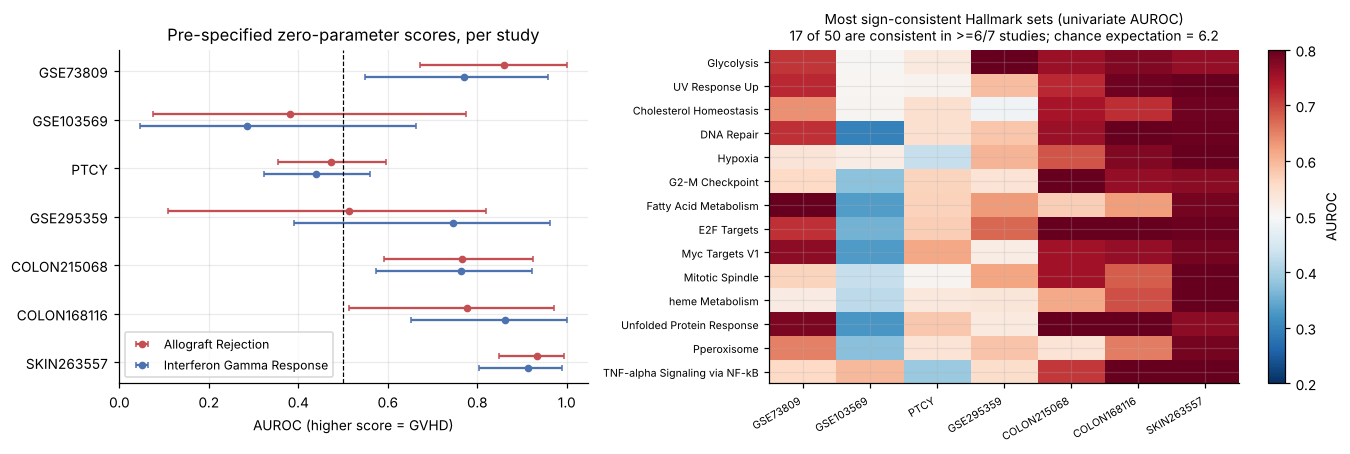

,study,score,auroc,lo,hi,scoreable
0,GSE73809,Allograft Rejection,0.86,0.67,1.00,True
1,GSE73809,Interferon Gamma Response,0.77,0.55,0.96,True
2,GSE103569,Allograft Rejection,0.38,0.08,0.77,True
3,GSE103569,Interferon Gamma Response,0.29,0.05,0.66,True
4,PTCY,Allograft Rejection,0.47,0.35,0.59,True
5,PTCY,Interferon Gamma Response,0.44,0.32,0.56,True
6,GSE295359,Allograft Rejection,0.51,0.11,0.82,True
7,GSE295359,Interferon Gamma Response,0.75,0.39,0.96,True
8,COLON215068,Allograft Rejection,0.77,0.59,0.92,True
9,COLON215068,Interferon Gamma Response,0.76,0.57,0.92,True


In [27]:
# ---------------------------------------------------------------- Zero-parameter biology panel (no fitting at all) and a chance calibration for "consistent pathways"
PRE = ['Allograft Rejection', 'Interferon Gamma Response']          # written down BEFORE any cohort was looked at (hallmark_eval.py docstring)
rows = []; uni = {}
for d in DIAG:
    P = POOL[d]; y = P['meta'].y.to_numpy().astype(int); g = P['meta'].patient.astype(str).to_numpy()
    uni[d] = np.array([auroc(y, P['H'][:, j]) for j in range(len(HNAMES))])
    for n in PRE:
        s = P['H'][:, HNAMES.index(n)]; b = group_bootstrap_auc(y, [s], g, 1000, seed=2)[0]
        rows.append(dict(study=d, score=n, auroc=auroc(y, s), lo=ci95(b)[0], hi=ci95(b)[1], scoreable=bool((P['H'][:, HNAMES.index(n)] != 0).any())))
panel = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={'width_ratios': [1, 1.25]})
for i, n in enumerate(PRE):
    q = panel[panel.score == n].reset_index(drop=True)
    ax[0].errorbar(q.auroc, np.arange(len(q)) + (i - .5) * .25, xerr=[q.auroc - q.lo, q.hi - q.auroc], fmt='o', color=['#C44E52', '#4C72B0'][i], label=n, capsize=2, ms=4)
ax[0].axvline(.5, color='k', lw=.8, ls='--'); ax[0].set_yticks(range(len(DIAG))); ax[0].set_yticklabels(DIAG); ax[0].invert_yaxis(); ax[0].set_xlabel('AUROC (higher score = GVHD)'); ax[0].legend(fontsize=8)
ax[0].set_title('Pre-specified zero-parameter scores, per study')
U = pd.DataFrame(uni, index=HNAMES)
cons = (U > .5).sum(1); order = np.argsort(-np.abs(cons.to_numpy() - 3.5))
n_cons = int(((cons >= 6) | (cons <= 1)).sum()); exp_chance = len(HNAMES) * 2 * (7 + 1) / 128
top = U.iloc[order[:14]]
im = ax[1].imshow(top.to_numpy(), cmap='RdBu_r', vmin=.2, vmax=.8, aspect='auto'); ax[1].set_xticks(range(len(DIAG))); ax[1].set_xticklabels(DIAG, rotation=30, ha='right', fontsize=7)
ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels([n.replace('HALLMARK_', '') for n in top.index], fontsize=7); plt.colorbar(im, ax=ax[1], label='AUROC')
ax[1].set_title(f'Most sign-consistent Hallmark sets (univariate AUROC)\n{n_cons} of 50 are consistent in >=6/7 studies; chance expectation = {exp_chance:.1f}', fontsize=9)
plt.tight_layout(); plt.show()
panel.round(2)

In [28]:
pt = panel.pivot(index='study', columns='score', values='auroc')
display(Markdown(f"""**Result.** The two pre-specified scores reach AUROC **{pt.loc['SKIN263557'].min():.2f}–{pt.loc['SKIN263557'].max():.2f} in skin**, **{pt.loc[['COLON215068','COLON168116']].min().min():.2f}–{pt.loc[['COLON215068','COLON168116']].max().max():.2f} in colon** and {pt.loc['GSE73809'].min():.2f}–{pt.loc['GSE73809'].max():.2f} in GSE73809 — with **no fitting**. They fail in sorted PtCy T cells ({pt.loc['PTCY'].min():.2f}–{pt.loc['PTCY'].max():.2f}) and in the homing-subset study GSE103569 ({pt.loc['GSE103569'].min():.2f}–{pt.loc['GSE103569'].max():.2f}, *below* 0.5). {n_cons} of 50 Hallmark sets are sign-consistent in ≥ 6/7 studies versus ~{exp_chance:.1f} expected by chance.
**Reading.** The classic alloimmune programme is a genuine, *model-free* signature of GvHD in inflamed **tissue** — a better "baseline to beat" than any learned head — but it is not what separates GvHD in sorted **blood T cells**, and sorted T cells after PtCy in particular (consistent with the idea that GvHD breaking through PtCy is biologically different; that is a hypothesis, not a finding, at n=88).
**A lead worth a pre-registered follow-up.** {n_cons} of 50 Hallmark sets keep their direction in ≥ 6/7 studies — about {n_cons / exp_chance:.1f}× the chance expectation — so a *shared* cross-study direction exists for a subset of programmes. A head restricted to such sets is a candidate design, but only if the sets are chosen **inside the training folds** (choosing them here, after seeing all 7 studies, would be circular)."""))

**Result.** The two pre-specified scores reach AUROC **0.91–0.93 in skin**, **0.76–0.86 in colon** and 0.77–0.86 in GSE73809 — with **no fitting**. They fail in sorted PtCy T cells (0.44–0.47) and in the homing-subset study GSE103569 (0.29–0.38, *below* 0.5). 17 of 50 Hallmark sets are sign-consistent in ≥ 6/7 studies versus ~6.2 expected by chance.
**Reading.** The classic alloimmune programme is a genuine, *model-free* signature of GvHD in inflamed **tissue** — a better "baseline to beat" than any learned head — but it is not what separates GvHD in sorted **blood T cells**, and sorted T cells after PtCy in particular (consistent with the idea that GvHD breaking through PtCy is biologically different; that is a hypothesis, not a finding, at n=88).
**A lead worth a pre-registered follow-up.** 17 of 50 Hallmark sets keep their direction in ≥ 6/7 studies — about 2.7× the chance expectation — so a *shared* cross-study direction exists for a subset of programmes. A head restricted to such sets is a candidate design, but only if the sets are chosen **inside the training folds** (choosing them here, after seeing all 7 studies, would be circular).

## E.9 Is the "forecast the next timepoint" objective (O6) learnable? — cfRNA month 1 → month 2
The only public longitudinal HSCT transcriptome (GSE268164) lets us ask the O6 question directly. Predict a patient's month-2 plasma cfRNA profile from month 1; the scores are median per-gene R² **relative to predicting the population mean**, compared with *persistence* (carry the month-1 deviation forward) and a ridge model over all genes; 5×5-fold patient-grouped CV.

54 patients with both month-1 and month-2 cfRNA, 5158 genes


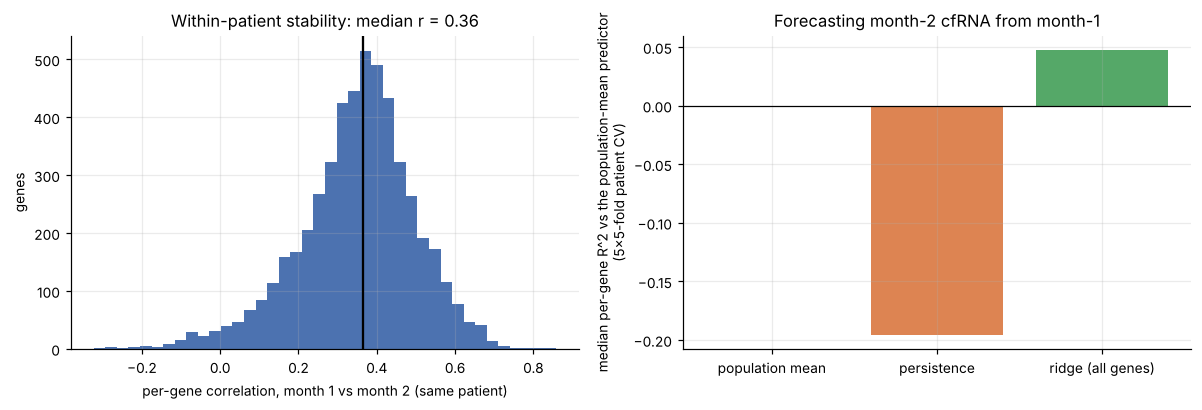

{'mean': 0.0, 'persistence': -0.195, 'ridge': 0.047}


In [29]:
# ---------------------------------------------------------------- Is the "next-timepoint forecasting" objective learnable on the only public longitudinal HSCT transcriptome (cfRNA)?
# Task: given a patient's month-1 plasma cfRNA profile, predict their month-2 profile.  Baselines: population mean, persistence (copy month 1).
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
cf = RAW['CFRNA268164']['meta']; Xcf = RAW['CFRNA268164']['X']; meas = np.isfinite(Xcf).all(0) & (np.nanstd(Xcf, 0) > 0)
def tp_matrix(tp): 
    ix = cf.index[cf.timepoint == tp]; return {cf.patient[i]: Xcf[i, meas] for i in ix}
a1, a2 = tp_matrix('1M'), tp_matrix('2M'); pats = sorted(set(a1) & set(a2))
X1 = np.array([a1[p] for p in pats]); X2 = np.array([a2[p] for p in pats]); print(f'{len(pats)} patients with both month-1 and month-2 cfRNA, {X1.shape[1]} genes')
def r2_per_gene(Y, P): return 1 - ((Y - P) ** 2).sum(0) / np.maximum(((Y - Y.mean(0)) ** 2).sum(0), 1e-12)
res = {k: [] for k in ('mean', 'persistence', 'ridge')}
for rep in range(5):
    P_mean, P_pers, P_ridge = (np.zeros_like(X2) for _ in range(3))
    for tr, te in KFold(5, shuffle=True, random_state=rep).split(X1):
        mu1, mu2 = X1[tr].mean(0), X2[tr].mean(0)
        P_mean[te] = mu2; P_pers[te] = X1[te] - mu1 + mu2                      # "persistence": month-1 deviation from the mean carries over
        P_ridge[te] = Ridge(alpha=X1.shape[1] * 3.0).fit(X1[tr] - mu1, X2[tr] - mu2).predict(X1[te] - mu1) + mu2
    base = ((X2 - P_mean) ** 2).sum(0)
    res['mean'].append(0.0); res['persistence'].append(float(np.median(1 - ((X2 - P_pers) ** 2).sum(0) / base))); res['ridge'].append(float(np.median(1 - ((X2 - P_ridge) ** 2).sum(0) / base)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
r_gene = np.array([np.corrcoef(X1[:, j], X2[:, j])[0, 1] for j in range(X1.shape[1])])
ax[0].hist(r_gene, bins=40, color='#4C72B0'); ax[0].axvline(np.median(r_gene), color='k'); ax[0].set_xlabel('per-gene correlation, month 1 vs month 2 (same patient)'); ax[0].set_ylabel('genes')
ax[0].set_title(f'Within-patient stability: median r = {np.median(r_gene):.2f}')
ax[1].bar(['population mean', 'persistence', 'ridge (all genes)'], [0.0, np.mean(res['persistence']), np.mean(res['ridge'])], color=['#BBBBBB', '#DD8452', '#55A868'])
ax[1].set_ylabel('median per-gene R^2 vs the population-mean predictor\n(5x5-fold patient CV)'); ax[1].set_title('Forecasting month-2 cfRNA from month-1'); ax[1].axhline(0, color='k', lw=.8)
plt.tight_layout(); plt.show(); print({k: round(float(np.mean(v)), 3) for k, v in res.items()})

In [30]:
display(Markdown(f"""**Result.** {len(pats)} patients, {X1.shape[1]} genes. Within-patient month-1/month-2 correlation per gene has median **{np.median(r_gene):.2f}**. Relative to the population mean: persistence **{np.mean(res['persistence']):+.2f}** (worse than the mean) and a ridge forecaster **{np.mean(res['ridge']):+.2f}** (marginally better).
**Reading.** Between-patient and between-draw variance dominate; a forecasting objective has **very little predictable temporal structure to learn from cfRNA at n≈54** — it would need denser sampling or a cleaner analyte. That does not rule O6 out in principle; it says that on public data it cannot currently be validated."""))

**Result.** 54 patients, 5158 genes. Within-patient month-1/month-2 correlation per gene has median **0.36**. Relative to the population mean: persistence **-0.20** (worse than the mean) and a ridge forecaster **+0.05** (marginally better).
**Reading.** Between-patient and between-draw variance dominate; a forecasting objective has **very little predictable temporal structure to learn from cfRNA at n≈54** — it would need denser sampling or a cleaner analyte. That does not rule O6 out in principle; it says that on public data it cannot currently be validated.

## E.10 Label-efficiency curves: how many labelled samples does each head need?
EHRSHOT-style: fit the head on *k* labelled samples drawn at random from the other six studies (15–40 draws per k; fixed penalty to keep this tractable) and score the held-out study; the right-most point uses *all* other samples with the penalty chosen by inner CV (the main LOSO number). Averaged over held-out studies **within each sample type**, because pooling tissue and blood hides the shape of the curves.

[cache] learning_curves.json  (computed 2026-10-24 02:38, 15s, repeats=4, perms=100)


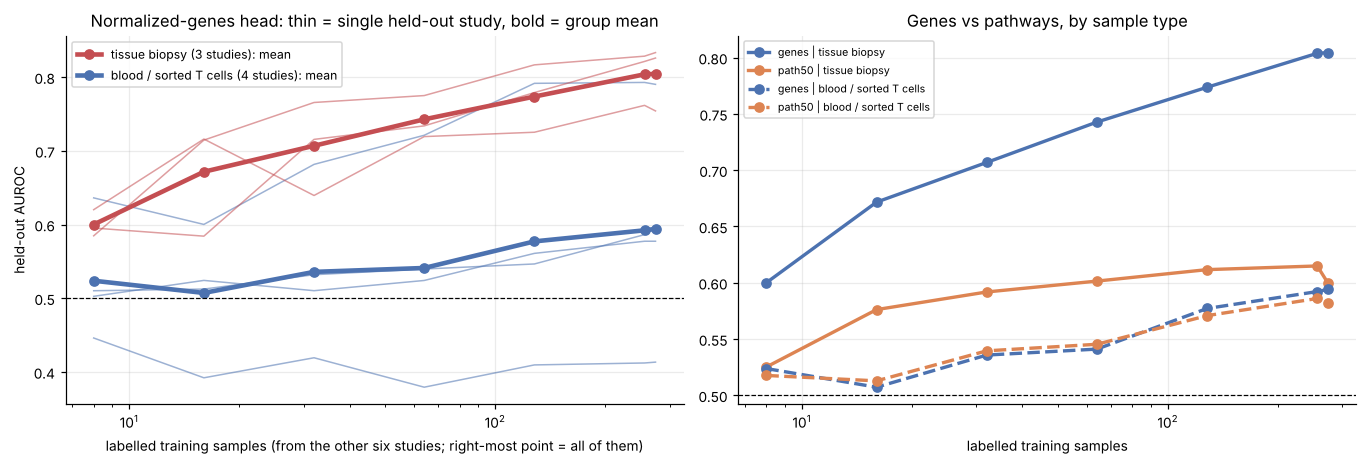

k=8   k=16   k=32   k=64  k=128  k=256  all (~274)
genes  tissue biopsy (3 studies)           0.600  0.672  0.707  0.743  0.774  0.804       0.804
       blood / sorted T cells (4 studies)  0.524  0.507  0.536  0.541  0.577  0.592       0.594
path50 tissue biopsy (3 studies)           0.525  0.576  0.592  0.601  0.612  0.615       0.599
       blood / sorted T cells (4 studies)  0.518  0.513  0.540  0.545  0.571  0.586       0.582

In [31]:
# ---------------------------------------------------------------- Label-efficiency (EHRSHOT-style): held-out-study AUROC as a function of the number of labelled training samples
KS = [8, 16, 32, 64, 128, 256]
def lc_one(a, held, n_draw, seed):
    """AUROC on `held` when only k labelled samples (drawn at random from the OTHER studies) are used to fit the head (fixed penalty, no inner CV)."""
    X = Xs[a]; rng = np.random.default_rng(seed); te = stu == held; pool_idx = np.where(~te)[0]; out = {}
    for k in KS:
        vals = []
        for _ in range(n_draw):
            for _try in range(50):
                idx = rng.choice(pool_idx, size=min(k, len(pool_idx)), replace=False)
                if min(y_all[idx].sum(), (1 - y_all[idx]).sum()) >= 2: break
            vals.append(auroc(y_all[te], make_head(FIXED_C[a]).fit(X[idx], y_all[idx]).decision_function(X[te])))
        out[str(k)] = float(np.nanmean(vals))
    return out
t0 = time.time()
jobs = [(a, h) for a in ('genes', 'path50') for h in DIAG]
res = cached('learning_curves', lambda: Parallel(n_jobs=N_JOBS)(delayed(lc_one)(a, h, N_DRAW, 7 + i) for i, (a, h) in enumerate(jobs)))
LC = {a: {} for a in ('genes', 'path50')}
for (a, h), r in zip(jobs, res):
    for k in KS: LC[a][(h, k)] = r[str(k)]
    LC[a][(h, 'all')] = LOSO[a][h]['auroc']                                                # all other studies, penalty chosen by inner CV (the main LOSO number)
n_full = {h: int((stu != h).sum()) for h in DIAG}; x_all = np.array(KS + [np.mean(list(n_full.values()))], float)
GROUPS = {'tissue biopsy (3 studies)': [d for d in DIAG if d in TISSUE], 'blood / sorted T cells (4 studies)': [d for d in DIAG if d not in TISSUE]}
def curves(a, studies): return np.array([[LC[a][(h, k)] for k in KS] + [LC[a][(h, 'all')]] for h in studies])
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
gcol = {'tissue biopsy (3 studies)': '#C44E52', 'blood / sorted T cells (4 studies)': '#4C72B0'}
for h in DIAG: ax[0].plot(x_all, curves('genes', [h])[0], lw=1, alpha=.55, color=gcol['tissue biopsy (3 studies)' if h in TISSUE else 'blood / sorted T cells (4 studies)'])
for gname, studies in GROUPS.items(): ax[0].plot(x_all, curves('genes', studies).mean(0), lw=3, marker='o', color=gcol[gname], label=f'{gname}: mean')
ax[0].axhline(.5, color='k', lw=.8, ls='--'); ax[0].set_xscale('log'); ax[0].set_xlabel('labelled training samples (from the other six studies; right-most point = all of them)')
ax[0].set_ylabel('held-out AUROC'); ax[0].set_title('Normalized-genes head: thin = single held-out study, bold = group mean'); ax[0].legend(fontsize=8)
for gname, studies in GROUPS.items():
    for a in ('genes', 'path50'):
        ax[1].plot(x_all, curves(a, studies).mean(0), lw=2.2, marker='o', ls='-' if gname.startswith('tissue') else '--', color=ARM_COLORS[a], label=f'{a} | {gname.split(" (")[0]}')
ax[1].axhline(.5, color='k', lw=.8, ls='--'); ax[1].set_xscale('log'); ax[1].set_xlabel('labelled training samples'); ax[1].set_title('Genes vs pathways, by sample type'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
lc_tab = pd.DataFrame({(a, g): curves(a, st).mean(0) for a in ('genes', 'path50') for g, st in GROUPS.items()}, index=[f'k={k}' for k in KS] + [f'all (~{int(x_all[-1])})']).T.round(3)
lc_tab

In [32]:
tg, bg = 'tissue biopsy (3 studies)', 'blood / sorted T cells (4 studies)'
L = lambda a, g, k: lc_tab.loc[(a, g), k]; per_doubling = (L('genes', tg, 'k=256') - L('genes', tg, 'k=64')) / 2
display(Markdown(f"""**Result.** Normalized-genes head — tissue studies: **{L('genes', tg, 'k=8'):.2f} → {L('genes', tg, 'k=32'):.2f} → {L('genes', tg, 'k=64'):.2f} → {L('genes', tg, 'k=256'):.2f}** at k = 8 / 32 / 64 / 256; blood / sorted T cells: **{L('genes', bg, 'k=8'):.2f} → {L('genes', bg, 'k=32'):.2f} → {L('genes', bg, 'k=64'):.2f} → {L('genes', bg, 'k=256'):.2f}**. Pathway head — tissue {L('path50', tg, 'k=8'):.2f} → {L('path50', tg, 'k=256'):.2f}, blood {L('path50', bg, 'k=8'):.2f} → {L('path50', bg, 'k=256'):.2f}.
**Reading.** (i) The pathway head is **not** more label-efficient: it starts at or below genes in both groups (tissue {L('path50', tg, 'k=8'):.2f} vs {L('genes', tg, 'k=8'):.2f} at k=8) and flattens, so its small parameter count buys no head-start. (ii) For tissue the genes curve is **still rising at k=256** (≈ +{per_doubling:.2f} AUROC per doubling between 64 and 256) — there is no plateau inside the ~{int(x_all[-1])} samples available, so more labelled tissue data would probably help; with only three held-out studies the slope is indicative, not precise. (iii) For blood the curves are nearly flat and single studies (GSE103569, PtCy) stay at or below ≈ 0.6 whatever k — the signature of **domain shift rather than sample shortage**, within the range available (≤ ~{int(x_all[-1])} samples). For data planning: more *tissue* labels look useful; more *cross-study blood* labels of the same kind, up to this size, do not; matched-protocol cohorts are what blood would need."""))

**Result.** Normalized-genes head — tissue studies: **0.60 → 0.71 → 0.74 → 0.80** at k = 8 / 32 / 64 / 256; blood / sorted T cells: **0.52 → 0.54 → 0.54 → 0.59**. Pathway head — tissue 0.53 → 0.61, blood 0.52 → 0.59.
**Reading.** (i) The pathway head is **not** more label-efficient: it starts at or below genes in both groups (tissue 0.53 vs 0.60 at k=8) and flattens, so its small parameter count buys no head-start. (ii) For tissue the genes curve is **still rising at k=256** (≈ +0.03 AUROC per doubling between 64 and 256) — there is no plateau inside the ~274 samples available, so more labelled tissue data would probably help; with only three held-out studies the slope is indicative, not precise. (iii) For blood the curves are nearly flat and single studies (GSE103569, PtCy) stay at or below ≈ 0.6 whatever k — the signature of **domain shift rather than sample shortage**, within the range available (≤ ~274 samples). For data planning: more *tissue* labels look useful; more *cross-study blood* labels of the same kind, up to this size, do not; matched-protocol cohorts are what blood would need.

---
# Part F — Synthesis

## F.1 Scorecard
Where does each arm sit on the claim ladder (D.3)? "Level 2" needs a gain of ≥ +0.03 over normalized genes whose study-level CI excludes 0, plus (for FMs) beating the random-weight twin.

In [33]:
# ---------------------------------------------------------------- Scorecard: where does each arm sit on the claim ladder (Part D.3)?
rows = []
base7 = [LOSO['genes'][d]['auroc'] for d in DIAG]
for arm in ('path50', 'moe50'):
    v = [LOSO[arm][d]['auroc'] for d in DIAG]; dm, lo, hi = boot_delta(v, base7)
    L2 = (dm >= .03) and (lo > 0) and (sum(x > y for x, y in zip(v, base7)) >= 5)
    L1 = dm >= -.02
    rows.append({'arm': arm, 'scope': '7-study LOSO', 'mean AUROC': np.mean(v), 'mean delta vs genes': dm, 'CI over studies': f'[{lo:+.3f}, {hi:+.3f}]',
                 'studies improved over genes': f'{sum(x > y for x, y in zip(v, base7))}/7', 'beats random-weight twin': 'n/a', 'ladder level reached (static)': 2 if L2 else (1 if L1 else 0)})
base4 = [LOSO4['genes'][d]['auroc'] for d in FM_STUDIES]
for arm, twin in (('gf10', 'rand10'), ('gf104', 'rand104'), ('gf316', 'rand316')):
    v = [LOSO4[arm][d]['auroc'] for d in FM_STUDIES]; w = [LOSO4[twin][d]['auroc'] for d in FM_STUDIES]
    dm, lo, hi = boot_delta(v, base4); tm, tlo, thi = boot_delta(v, w)
    L2 = (dm >= .03) and (lo > 0) and (tlo > 0)
    rows.append({'arm': arm, 'scope': '4-study LOSO (RNA-seq)', 'mean AUROC': np.mean(v), 'mean delta vs genes': dm, 'CI over studies': f'[{lo:+.3f}, {hi:+.3f}]',
                 'studies improved over genes': f'{sum(x > y for x, y in zip(v, base4))}/4', 'beats random-weight twin': f'{tm:+.3f} [{tlo:+.3f}, {thi:+.3f}]', 'ladder level reached (static)': 2 if L2 else (1 if dm >= -.02 else 0)})
score = pd.DataFrame(rows).set_index('arm'); score[['mean AUROC', 'mean delta vs genes']] = score[['mean AUROC', 'mean delta vs genes']].round(3)
print('Level 1 here = mean LOSO within 0.02 of normalized genes (the label-efficiency half of Level 1 is assessed in E.10); Level 2 = +0.03, CI over studies excludes 0, and beats the random-weight twin / improves >=5 of 7.')
score

Level 1 here = mean LOSO within 0.02 of normalized genes (the label-efficiency half of Level 1 is assessed in E.10); Level 2 = +0.03, CI over studies excludes 0, and beats the random-weight twin / improves >=5 of 7.


,scope,mean AUROC,mean delta vs genes,CI over studies,studies improved over genes,beats random-weight twin,ladder level reached (static)
arm,,,,,,,
path50,7-study LOSO,0.589,-0.095,"[-0.208, -0.001]",2/7,n/a,0
moe50,7-study LOSO,0.608,-0.076,"[-0.162, +0.003]",3/7,n/a,0
gf10,4-study LOSO (RNA-seq),0.498,-0.258,"[-0.384, -0.127]",0/4,"-0.049 [-0.136, +0.020]",0
gf104,4-study LOSO (RNA-seq),0.678,-0.078,"[-0.125, -0.031]",0/4,"+0.064 [+0.035, +0.104]",0
gf316,4-study LOSO (RNA-seq),0.615,-0.141,"[-0.253, -0.028]",0/4,"-0.037 [-0.072, +0.014]",0


In [34]:
display(Markdown(f"""**Reading the scorecard.** No pathway or foundation-model arm reaches Level 2 (and none improves on normalized genes in a majority of held-out studies). Only Geneformer-104M clears the *weaker* test of beating its random-weight twin ({score.loc['gf104', 'beats random-weight twin']}). The strongest generic model in this benchmark is the **ridge head on normalized vocabulary genes (LOSO {np.mean([LOSO['genes'][d]['auroc'] for d in DIAG]):.3f})** — and the strongest *model-free* baseline is the pre-specified IFN-γ/allograft-rejection score in inflamed tissue (E.8). Any future FM has to beat those, study by study."""))

**Reading the scorecard.** No pathway or foundation-model arm reaches Level 2 (and none improves on normalized genes in a majority of held-out studies). Only Geneformer-104M clears the *weaker* test of beating its random-weight twin (+0.064 [+0.035, +0.104]). The strongest generic model in this benchmark is the **ridge head on normalized vocabulary genes (LOSO 0.684)** — and the strongest *model-free* baseline is the pre-specified IFN-γ/allograft-rejection score in inflamed tissue (E.8). Any future FM has to beat those, study by study.

## F.2 What N is needed? — three independent estimates, then what exists
The question has three different answers depending on what is being claimed. All numbers below are computed above.

In [35]:
rn = lambda P, A=.75, pr=.4: riley_n(P, A, pr)['n']
hw = prec.loc[100, 'AUROC 0.7, prevalence 0.4']; hw400 = prec.loc[400, 'AUROC 0.7, prevalence 0.4']
def n80(delta, rho):
    v = pw_tab[(pw_tab.delta_AUROC == delta) & (pw_tab.score_corr == rho)].iloc[0]['n_for_80pct_power']; return v if isinstance(v, str) else f'{int(v):,}'
display(Markdown(f"""**(1) To *measure* a single AUROC well.** With 100 patients (prevalence 0.4, true AUROC 0.70) the 95 % CI half-width is ±**{hw:.2f}**; with 400 patients ±**{hw400:.2f}**. Every study in this notebook has ≤ 102 samples (largest blood T-cell study 88; largest cohort 92 patients), so single-study AUROCs are inherently ±0.1–0.2.

**(2) To *show that one model beats another*.** A paired DeLong test (baseline AUROC 0.70, prevalence 0.4) reaches 80 % power for ΔAUROC = 0.10 at about **{n80(.10, .8)}–{n80(.10, .5)}** patients, for Δ = 0.05 at **{n80(.05, .8)}–{n80(.05, .5)}**, and for Δ = 0.03 at **{n80(.03, .8)}–{n80(.03, .5)}** (range = model-score correlation 0.8 → 0.5). Δ = 0.03–0.05 is the scale at which a pretrained representation would have to beat a good baseline to matter in practice.

**(3) To *develop* a prediction model that is calibrated and doesn't overfit** (Riley criteria, target AUROC 0.75, prevalence 0.4, unpenalised): a 1–5-parameter score needs **{rn(5)}** patients, 10 parameters **{rn(10)}**, a 50-parameter head **{rn(50):,}**, a 768-parameter FM-embedding head **{rn(768):,}**, a 3,072-gene head **{rn(3072):,}**. These are conservative for *ridge*-penalised heads — which is why the empirical curve below matters — but they show how steeply the requirement grows with head size.

**Empirical complement — label-efficiency curves (E.10).** For normalized genes, held-out AUROC on the *tissue* studies climbs from **{lc_tab.loc[('genes', 'tissue biopsy (3 studies)'), 'k=8']:.2f}** (8 labelled samples) to **{lc_tab.loc[('genes', 'tissue biopsy (3 studies)'), 'k=64']:.2f}** (64) and **{lc_tab.loc[('genes', 'tissue biopsy (3 studies)'), 'k=256']:.2f}** (256) and is **still rising** inside the ~{int(x_all[-1])} samples available; on the *blood / sorted T-cell* studies it moves only from **{lc_tab.loc[('genes', 'blood / sorted T cells (4 studies)'), 'k=8']:.2f}** to **{lc_tab.loc[('genes', 'blood / sorted T cells (4 studies)'), 'k=256']:.2f}**. So where a transferable signal exists, more labelled data of the right kind helps and ~270 samples have not exhausted it; where it does not, adding cross-study blood samples up to that size does not create it — the binding constraint for blood looks like **between-study heterogeneity, not n alone**. A single power-law extrapolation to "the n that reaches 0.80" would hide this (the two groups have different curve shapes), so none is reported.

**What exists.** Public labelled blood/T-cell GvHD at sampling: **220 samples (4 studies)**; tissue: **{sum(len(POOL[d]['meta']) for d in TISSUE)} (3)**; longitudinal cfRNA: **92 patients**. Restricted: BMT CTN 1703 randomised **431** patients (Bolaños-Meade 2023); the MAGIC day-7 biomarker cohort **1,287** patients. So a **≤ 10-parameter score is within reach of one restricted trial; a 50-parameter pathway head is ≈ {rn(50)/431:.0f}× beyond it; a 768-parameter FM head ≈ {rn(768)/431:.0f}× beyond it** unless penalisation/transfer closes the gap — which is precisely what the FM would have to demonstrate."""))

**(1) To *measure* a single AUROC well.** With 100 patients (prevalence 0.4, true AUROC 0.70) the 95 % CI half-width is ±**0.11**; with 400 patients ±**0.05**. Every study in this notebook has ≤ 102 samples (largest blood T-cell study 88; largest cohort 92 patients), so single-study AUROCs are inherently ±0.1–0.2.

**(2) To *show that one model beats another*.** A paired DeLong test (baseline AUROC 0.70, prevalence 0.4) reaches 80 % power for ΔAUROC = 0.10 at about **200–400** patients, for Δ = 0.05 at **400–1,600**, and for Δ = 0.03 at **1,600–3,200** (range = model-score correlation 0.8 → 0.5). Δ = 0.03–0.05 is the scale at which a pretrained representation would have to beat a good baseline to matter in practice.

**(3) To *develop* a prediction model that is calibrated and doesn't overfit** (Riley criteria, target AUROC 0.75, prevalence 0.4, unpenalised): a 1–5-parameter score needs **369** patients, 10 parameters **445**, a 50-parameter head **2,224**, a 768-parameter FM-embedding head **34,151**, a 3,072-gene head **136,601**. These are conservative for *ridge*-penalised heads — which is why the empirical curve below matters — but they show how steeply the requirement grows with head size.

**Empirical complement — label-efficiency curves (E.10).** For normalized genes, held-out AUROC on the *tissue* studies climbs from **0.60** (8 labelled samples) to **0.74** (64) and **0.80** (256) and is **still rising** inside the ~274 samples available; on the *blood / sorted T-cell* studies it moves only from **0.52** to **0.59**. So where a transferable signal exists, more labelled data of the right kind helps and ~270 samples have not exhausted it; where it does not, adding cross-study blood samples up to that size does not create it — the binding constraint for blood looks like **between-study heterogeneity, not n alone**. A single power-law extrapolation to "the n that reaches 0.80" would hide this (the two groups have different curve shapes), so none is reported.

**What exists.** Public labelled blood/T-cell GvHD at sampling: **220 samples (4 studies)**; tissue: **100 (3)**; longitudinal cfRNA: **92 patients**. Restricted: BMT CTN 1703 randomised **431** patients (Bolaños-Meade 2023); the MAGIC day-7 biomarker cohort **1,287** patients. So a **≤ 10-parameter score is within reach of one restricted trial; a 50-parameter pathway head is ≈ 5× beyond it; a 768-parameter FM head ≈ 79× beyond it** unless penalisation/transfer closes the gap — which is precisely what the FM would have to demonstrate.

## F.3 What would change the conclusion (falsifiable, in order of cost)

| If this happened… | …the claim moves to | How to test it with this suite |
|---|---|---|
| A pretrained arm beats **both** its random-weight twin and normalized genes in LOSO by ≥ 0.03 on ≥ 5 of 7 studies | Level 2 | Re-run E.2/E.6 with the new model; no code changes |
| Gains appear only at ≤ 32 labels (label-efficiency) but vanish with more | Level 1 ("label-efficient") | E.10 curves per arm; paired over studies |
| A model pretrained on **allo-HSCT-adjacent** cells (alloimmune T cells, inflamed GI tissue) beats one pretrained on generic PBMC at equal size | the *domain* matters, not just scale | pretrain twin models; evaluate on Tiers 1–2 |
| Performance rises monotonically with pretraining cells (1 % → 10 % → 100 % of the public corpus) | scale is binding | scaling experiment (F.4, stage 2); contrast with the plateau reported in the cited scale study |
| A landmark model (blood at d+7/+14) beats **clinical-only + Ann Arbor/MAGIC biomarkers** in leave-centre-out | Level 3 | needs restricted cohorts (stage 3) |

## F.4 Roadmap with go / no-go gates

| Stage | Work | Needs | **Go / no-go** |
|---|---|---|---|
| **0 — now (public data)** | Release this benchmark, code, bundle, QC findings and negative results | nothing new | Done when the notebook runs end-to-end on Colab |
| **1 — widen the public labelled set** | Curate the remaining GEO series with ≥ 20 samples (36 human GvHD series on the census), obtain patient IDs and sampling dates from authors, harmonise with `build_bundle.py` | author e-mails; ~weeks | Proceed if ≥ 12 studies / ≥ 400 labelled diagnostic samples with patient IDs |
| **2 — pretraining + scaling experiment** | Pretrain O1 + O3 (+ O4) on the ~10⁷ public immune cells in two sizes; train at 1 %, 10 %, 100 % of the corpus; evaluate Tiers 0–2 with random-weight twins | GPU days (modest) | Go on only if a pretrained arm reaches Level 1 at stage-1 scale; stop and publish the negative if it does not |
| **3 — restricted clinical cohorts** | Apply for BMT CTN 1703 (randomised PtCy vs Tac/MTX, n=431) via dbGaP/BioLINCC, MAGIC and CIBMTR collaborations; run Tier 3 landmark tasks | institutional affiliation, data-use agreement | Riley n for the chosen head size (D.1): a ≤ 10-parameter score is supportable at n≈450; a 50-parameter head is not |
| **4 — prospective / temporal validation** | Freeze the model and score a later cohort or a second continent | collaborator site | Level 3 only if calibration and decision-curve benefit hold |

## F.5 How to frame this result honestly (and usefully)

The strongest *defensible* contribution available today is not a model — it is **a leakage-controlled benchmark and a quantitative answer to "how much data would a GvHD transcriptomic foundation model need?"**:

1. **A task suite and protocol** (Part D) with mandatory dumb baselines, random-weight twins, confounder-only models, a pre-stated gate and a claim ladder.
2. **The first multi-study evaluation of frozen Geneformer (10M / 104M / 316M) on GvHD**, with matched random-weight controls, across blood and tissue.
3. **A replication failure**: a knowledge-prior advantage seen on four studies did not survive a pre-stated seven-study test (Part E) — which is exactly the kind of result benchmarks exist to produce.
4. **A data-quality finding**: a public supplementary matrix contained 4 empty libraries (2 of its 9 control biopsies); removing them changed headline AUROCs only slightly but left just 7 control skin samples, which is why every skin CI is wide (E.1b).
5. **The N calculator** and learning-curve extrapolation: what sample size each head size needs, versus what is public and what restricted cohorts hold.

Suggested working title: *"Transcriptomic foundation models for graft-versus-host disease: a leakage-controlled benchmark and sample-size analysis."*

**Limitations that must travel with every number here**: small studies (7–101 samples each); PtCy patient IDs unavailable; GSE295359 has 10 patients; CIs reflect patients not samples but cannot fix confounding by centre/protocol; sample type and timing relative to GvHD onset are heterogeneous; Geneformer was used frozen (fine-tuning at n≈30 is not meaningful); label-free per-block normalisation needs a batch of samples at deployment; all learning-curve extrapolations are projections.

In [36]:
# ---------------------------------------------------------------- Consistency checks: the numbers quoted in the executive summary must match what was computed
if QUICK:
    print('QUICK mode: summary checks skipped (the summary quotes the full run).')
else:
    ck = {'genes LOSO mean': (np.mean([LOSO['genes'][d]['auroc'] for d in DIAG]), 0.684), 'path50 LOSO mean': (np.mean([LOSO['path50'][d]['auroc'] for d in DIAG]), 0.589),
          'shuffled control mean': (shuf.mean(1).mean(), 0.623), 'path50 4-study (restricted training)': (np.mean(list(orig['path50'].values())), 0.686),
          'gf104 - twin (4-study LOSO)': (float(score.loc['gf104', 'beats random-weight twin'].split(' ')[0]), 0.064),
          'tissue genes LOSO': (ctx_tab.loc['tissue biopsy (3 studies)', 'genes'], 0.804), 'Riley n, 50 params': (riley_n(50, .75, .4)['n'], 2224)}
    bad = {k: v for k, v in ck.items() if abs(v[0] - v[1]) > (0.01 if v[1] < 10 else 25)}
    print(pd.DataFrame(ck, index=['computed', 'quoted in summary']).T.round(3).to_string()); assert not bad, f'summary out of date: {bad}'; print('all quoted numbers match the computed results')

                                      computed  quoted in summary
genes LOSO mean                          0.684              0.684
path50 LOSO mean                         0.589              0.589
shuffled control mean                    0.623              0.623
path50 4-study (restricted training)     0.686              0.686
gf104 - twin (4-study LOSO)              0.064              0.064
tissue genes LOSO                        0.804              0.804
Riley n, 50 params                    2224.000           2224.000
all quoted numbers match the computed results


---
## References (✓ = confirmed against a search result during this project; † = cited from memory, verify before use)

1. Theodoris CV *et al.* Transfer learning enables predictions in network biology. *Nature* 618:616–624 (2023). ✓
2. Cui H *et al.* scGPT: toward building a foundation model for single-cell multi-omics using generative AI. *Nat Methods* (2024). doi:10.1038/s41592-024-02201-0 ✓
3. Hao M *et al.*† Large-scale foundation model on single-cell transcriptomics (scFoundation). *Nat Methods* (2024). doi:10.1038/s41592-024-02305-7 ✓ (title/DOI)
4. Rosen Y *et al.* Universal Cell Embeddings: a foundation model for cell biology. bioRxiv (2023). doi:10.1101/2023.11.28.568918 ✓
5. Yang F *et al.* scBERT as a large-scale pretrained deep language model for cell type annotation. *Nat Mach Intell* (2022). †
6. Gélard *et al.* BulkRNABert: cancer prognosis from bulk RNA-seq based language models. *PMLR* 259 (ML4H 2025). ✓
7. TEDDY: a family of foundation models for understanding single cell biology. arXiv:2503.03485. ✓
8. Kedzierska KZ, Crawford L, Amini AP, Lu AX. Zero-shot evaluation reveals limitations of single-cell foundation models. *Genome Biol* (2025). doi:10.1186/s13059-025-03574-x ✓
9. Boiarsky R *et al.* Deeper evaluation of a single-cell foundation model. *Nat Mach Intell* (2024); preprint "A deep dive into single-cell RNA sequencing foundation models", bioRxiv doi:10.1101/2023.10.19.563100 ✓
10. Ahlmann-Eltze C, Huber W, Anders S. Deep-learning-based gene perturbation effect prediction does not yet outperform simple linear baselines. *Nat Methods* 22:1657–1661 (2025). doi:10.1038/s41592-025-02772-6 ✓
11. Evaluating the role of pretraining dataset size and diversity on single-cell foundation model performance. bioRxiv doi:10.1101/2024.12.13.628448; *Nat Methods* (2026) doi:10.1038/s41592-026-03120-y ✓ (author list not confirmed)
12. Luecken MD *et al.* Benchmarking atlas-level data integration in single-cell genomics. *Nat Methods* 19:41–50 (2022). doi:10.1038/s41592-021-01336-8 ✓
13. Wornow M *et al.* EHRSHOT: an EHR benchmark for few-shot evaluation of foundation models. NeurIPS Datasets & Benchmarks (2023); arXiv:2307.02028 ✓
14. Harutyunyan H *et al.* Multitask learning and benchmarking with clinical time series data. *Sci Data* 6:96 (2019). ✓
15. Collins GS *et al.* TRIPOD+AI statement. *BMJ* 385:e078378 (2024). ✓  ·  Wolff RF *et al.* PROBAST. *Ann Intern Med* (2019). †
16. Riley RD *et al.* Calculating the sample size required for developing a clinical prediction model. *BMJ* 368:m441 (2020) ✓; Riley RD *et al.* *Stat Med* (2019) and the `pmsampsize` package ✓ (criteria 2–3 as implemented here: †).
17. Hanley JA, McNeil BJ. *Radiology* (1982) †; DeLong ER *et al.* *Biometrics* (1988) †; Sun X, Xu W. *IEEE Signal Process Lett* (2014) †.
18. Levine JE *et al.* A prognostic score for acute graft-versus-host disease based on biomarkers: a multicentre study. *Lancet Haematol* 2:e21–e29 (2015). doi:10.1016/S2352-3026(14)00035-0 ✓
19. Day-7 two-biomarker (ST2 + REG3α) algorithm, 1,287 patients: *JCI Insight* (2017), article 89798 ✓ (first author Hartwell†).
20. Bolaños-Meade J *et al.* Post-transplantation cyclophosphamide–based GVHD prophylaxis (BMT CTN 1703). *N Engl J Med* 388:2338–2348 (2023). doi:10.1056/NEJMoa2215943 ✓

**Data** (GEO): GSE73809, GSE103569, GSE4624, GSE182610 / GSE182612 / GSE182678 (PtCy), GSE295359, GSE215068, GSE168116, GSE263557, GSE268164. CELLxGENE Discover collections listed in Part B.

---
## Appendix — reproducibility and files
* **Repository layout** (`benchmark/`): `data/hsct_bundle.npz` (expression), `hsct_samples.csv`, `hallmark50.json`, `vocab_genes.json`, `geo_census.json`, `qc_removed.csv`, `geneformer_embeddings.npz`; `results/*.json` (cached slow cells); `build_bundle.py`, `embed_geneformer.py`, `merge_embeddings.py` (scripts as run); `evidence/` (logs of the earlier experiments cited in C.3).
* **Seeds**: global 20241023; permutation, bootstrap and control seeds are fixed in the cells. **Determinism**: BLAS thread order can change the last digit of an AUROC; the consistency check uses tolerances.
* **Geneformer**: weights and dictionaries from the Hugging Face repo `ctheodoris/Geneformer` (V1-10M, V2-104M, V2-316M); the first-run PtCy embeddings were regression-tested against `embed_geneformer.py` (bit-identical on the three samples tested for each of 10M / 104M / 316M, pretrained and random). Dictionaries are loaded through a numpy-scalar-only unpickler, never plain `pickle.load`.
* **Regenerating the bundle** needs the project's cached GEO downloads (sha256-pinned in the original pipeline); the committed bundle is what every number here uses.
* **Run time**: `RECOMPUTE=False` ≈ 6–10 min; `RECOMPUTE=True` ≈ 45 min (4 cores) — the permutation nulls in E.5 dominate.